# Jella et al. (2025) — Noisy Hopf reproduction, Phase 1

**Primary source:** [original PDF](<../paper/10 Recurrence condensation during critical transitions in complex systems.pdf>),
*Chaos* **35**, 083107, [DOI](https://doi.org/10.1063/5.0267157).
The existing [research discussion](../sumarize_paper/Jella_2025_discussion.md)
provides context; Eq. (1), Sections II.B–D and III.C, and captions of Figs. 5–8
control the numerical interpretation. The user-selected notebook name is retained.

This is a methodological foundation: stochastic integration, amplitude and
initial-state diagnostics, delay reconstruction, recurrence matrices and eight
RQA measures. Every plot is a **diagnostic**, not a full reproduction of Figs. 5–8.
No exponent fitting, candidate critical-point search, experimental-data analysis,
ISS or prediction method is implemented. The known deterministic linear condition
α = β = 50 is used only to choose illustrative conditions and check the equations.
All results and interpretations stay here; no simulation cache or external
analysis module is written.

## 1. Source and convention audit

| Item | Paper specification | Implementation choice | Status |
|---|---|---|---|
| Model | Eq. (1), additive acceleration noise | Exact first-order SDE below, including both printed signs of γ | Reported equation |
| Oscillator | ω=2π×120, β=50; subcritical K=9, γ=0.7; supercritical K=−9, γ=−0.7 | Same values; α=80,60,52,50,49,45 independent starts | Parameters reported; six-point grid selected |
| Noise | ⟨ξ(t)ξ(s)⟩=Γδ(t−s), Γ=10 | dv diffusion √Γ; exact linear stochastic-convolution covariance | Covariance reported; SDE interpretation derived |
| Integration | Not specified in Sections II.B/III.C or captions | Symmetric nonlinear / exact linear-noise / nonlinear splitting | Selected, validated below |
| Time step | No Hopf step reported | h=50 μs; checks at 100/50/25 μs | Selected, not author settings |
| Recorded samples | No Hopf sampling rate reported; 10 kHz belongs to the experiment | 2 kHz coarse pilot; 10 kHz final RQA baseline, separately audited; no smoothing | Selected; 16.67 samples per natural period |
| Initial state | Not specified | (η,v)=(0,0), independent noise realizations; alternate states labeled | Selected |
| Transients | Not specified | Discard 30 s; retain 3 s; inspect discard/seed sensitivity | Selected, not universal stationarity proof |
| Embedding | Cao dimension and AMI delay | Histogram AMI and Cao E1/E2 per selected condition; rules/fallback explicit | Methods reported; numerical estimates reproduced |
| Distance/scaling | Euclidean embedded distance; normalization unspecified | Scalar z-score per window before embedding; no coordinate-wise rescaling | Norm reported; normalization selected |
| Recurrence threshold | Fixed ε for displays; quantitative RR=0.05 | Closest attainable 5% including self-pairs; ties preserved | Target reported; calibration policy selected |
| Minimum lengths | l_min=v_min=k_min=2 | Inclusive ≥2, following summation limits | Reported; prose sometimes says > |
| Main diagonal / Theiler | Not resolved | RR includes diagonal; diagonal-line histogram excludes LOI; verticals retain it; no additional Theiler exclusion | Selected primary policy |
| Boundary lines / entropies | Not resolved completely | Black runs include truncated boundaries; white runs need two bounding recurrences; entropy over eligible lines, natural log | Selected; alternatives audited |
| RQA windows | 1,500 samples, average window measures; moving-window wording but step absent | Non-overlapping raw windows, four at 2 kHz / twenty at 10 kHz; per-window embedding/calibration, strict NaN | Length/averaging reported; step and invalidity selected |

The printed supercritical γ<0 makes the high-amplitude nonlinear damping
positive: the model is **not globally confining**. It is retained literally;
local small-amplitude behavior and the tested initial states must not be extended
to claims of a globally bounded stationary SDE. Likewise, the paper's abrupt
subcritical jump at α=50 need not occur during a finite run from a noisy origin.

In [1]:
import hashlib
import json
import math
import platform
from time import perf_counter

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from IPython.display import Markdown, display
from scipy.integrate import solve_ivp
from scipy.linalg import expm
from scipy.signal import detrend, welch
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist, pdist, squareform

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("Python", platform.python_version(), "; NumPy", np.__version__)
print("SciPy", scipy.__version__, "; Matplotlib", matplotlib.__version__)

Python 3.12.10 ; NumPy 2.5.3
SciPy 1.18.1 ; Matplotlib 3.11.2


In [2]:
MODEL = {"omega": 2 * np.pi * 120, "beta": 50.0, "Gamma": 10.0}
CONFIGS = {
    "subcritical": {"K": 9.0, "gamma": 0.7},
    "supercritical": {"K": -9.0, "gamma": -0.7},
}
ALPHAS = (80, 60, 52, 50, 49, 45)
H = 5e-5
OUTPUT_DT = 5e-4
DISCARD = 30.0
RETAIN = 3.0
MASTER_SEED = 2025083107
WINDOW = 1500
TARGET_RR = 0.05
LINE_MIN = 2
MAX_VECTORS = 1600
METRICS = ("RR", "DET", "L", "Entr", "LAM", "TT", "RT", "RTE")


def show_table(headers, rows):
    headers = [str(h).replace("|", r"\|") for h in headers]
    lines = [
        "| " + " | ".join(headers) + " |",
        "|" + "|".join("---" for _ in headers) + "|",
    ]
    lines.extend(
        "| " + " | ".join(str(v).replace("|", r"\|") for v in r) + " |"
        for r in rows
    )
    display(Markdown("\n".join(lines)))


def rng_for(purpose, alpha, replicate=0, kind=0):
    seed = np.random.SeedSequence(
        [MASTER_SEED, purpose, int(round(10 * alpha)), replicate, kind]
    )
    return np.random.Generator(np.random.PCG64(seed))


def rms(values):
    return float(np.sqrt(np.mean(np.square(values))))

## 2. Eq. (1), units and deterministic linear stability

Let x=η and v=dη/dt. Then dx=v dt and
\[
dv=[(eta-lpha+Kx^2-\gamma x^4)v-\omega^2x]dt+
\sqrt{\Gamma}\,dW,\qquad E[(dW)^2]=dt.
\]
Itô and Stratonovich drift agree because diffusion is constant. If η has unit A,
Γ has units A²/s³; the acceleration-noise impulse has variance Γh in velocity.
It is neither Γh times a unit normal nor a fresh noise value of amplitude Γ
inserted into an ODE derivative without the required time scaling.

The deterministic Jacobian at (0,0) is [[0,1],[−ω²,β−α]]. Its trace is β−α and
determinant ω²>0, so eigenvalue real parts cross zero at α=β=50. The origin is
linearly stable for α>50 and unstable for α<50; at 50 linear theory alone does
not settle nonlinear stability. With Γ>0 the trajectory cannot remain exactly
at that origin: noise acts on v and is transmitted to x.

In [3]:
def hopf_drift(state, alpha, configuration):
    x, v = state
    nonlinear = configuration["K"] * x**2 - configuration["gamma"] * x**4
    return np.array(
        [v, (MODEL["beta"] - alpha + nonlinear) * v - MODEL["omega"] ** 2 * x]
    )


for configuration in CONFIGS.values():
    np.testing.assert_array_equal(
        hopf_drift((0, 0), 60, configuration), [0, 0]
    )
    x, v, alpha = 0.2, 0.3, 52
    original = (
        -alpha * v
        - MODEL["omega"] ** 2 * x
        + v
        * (
            MODEL["beta"]
            + configuration["K"] * x**2
            - configuration["gamma"] * x**4
        )
    )
    np.testing.assert_allclose(
        hopf_drift((x, v), alpha, configuration)[1], original, rtol=1e-14
    )
linear_rows = []
for alpha in ALPHAS:
    matrix = np.array(
        [[0, 1], [-(MODEL["omega"] ** 2), MODEL["beta"] - alpha]]
    )
    eigenvalues = np.linalg.eigvals(matrix)
    np.testing.assert_allclose(eigenvalues.real, (50 - alpha) / 2, atol=1e-12)
    linear_rows.append(
        [
            alpha,
            f"{eigenvalues[0].real:.3f}",
            f"{abs(eigenvalues[0].imag) / (2 * np.pi):.5f}",
        ]
    )
show_table(
    ["alpha", "Linear growth rate / s", "Damped frequency / Hz"], linear_rows
)
print("Natural period:", 2 * np.pi / MODEL["omega"], "s")

| alpha | Linear growth rate / s | Damped frequency / Hz |
|---|---|---|
| 80 | -15.000 | 119.97625 |
| 60 | -5.000 | 119.99736 |
| 52 | -1.000 | 119.99989 |
| 50 | 0.000 | 120.00000 |
| 49 | 0.500 | 119.99997 |
| 45 | 2.500 | 119.99934 |

Natural period: 0.008333333333333333 s


### 2.1 Cycle-averaged amplitude structure, not a fitted bifurcation diagram

For nearly sinusoidal x≈a cos(ωt), averaging the deterministic energy gives
\[
\dot approx(eta-lpha)a/2+Ka^3/8-\gamma a^5/16.
\]
Positive q=a² satisfy γq²−2Kq−8(β−α)=0. For the subcritical signs the averaged
fold is α≈50+K²/(8γ)=64.4643: at α=60 there are predicted unstable a≈2.39 and
stable a≈4.47 cycles in addition to a stable origin. This is a weak-damping
approximation, not an exact global bifurcation calculation. For the printed
supercritical signs a small stable cycle exists below 50 and an outer unstable
branch bounds its local basin; the leading high-amplitude term is antidamping.

In [4]:
def averaged_cycles(alpha, configuration):
    k, gamma = configuration["K"], configuration["gamma"]
    roots = np.roots([gamma, -2 * k, -8 * (50 - alpha)])
    result = []
    for q in sorted(
        r.real for r in roots if abs(r.imag) < 1e-10 and r.real > 0
    ):
        amplitude = np.sqrt(q)
        derivative = (50 - alpha) / 2 + 3 * k * q / 8 - 5 * gamma * q * q / 16
        result.append(
            (float(amplitude), "stable" if derivative < 0 else "unstable")
        )
    return result


show_table(
    ["Hopf signs", "alpha", "Averaged positive cycles (a, stability)"],
    [
        [name, alpha, str(averaged_cycles(alpha, cfg))]
        for name, cfg in CONFIGS.items()
        for alpha in (60, 52, 50, 49, 45)
    ],
)

| Hopf signs | alpha | Averaged positive cycles (a, stability) |
|---|---|---|
| subcritical | 60 | [(2.390457218668787, 'unstable'), (4.47213595499958, 'stable')] |
| subcritical | 52 | [(0.9601789790880737, 'unstable'), (4.979190902385959, 'stable')] |
| subcritical | 50 | [(5.0709255283711, 'stable')] |
| subcritical | 49 | [(5.113834471217055, 'stable')] |
| subcritical | 45 | [(5.269901938490012, 'stable')] |
| supercritical | 60 | [(5.4385791094365326, 'unstable')] |
| supercritical | 52 | [(5.155036802879054, 'unstable')] |
| supercritical | 50 | [(5.0709255283711, 'unstable')] |
| supercritical | 49 | [(0.6726096953158708, 'stable'), (5.026119965943193, 'unstable')] |
| supercritical | 45 | [(1.5674775508620218, 'stable'), (4.822582279425548, 'unstable')] |

## 3. Exact linear-noise splitting and reproducible random paths

Euler–Maruyama's deterministic linear factor has modulus greater than one unless
h<(α−β)/ω² for α>β, and it spuriously amplifies the undamped oscillator at
α=β for every h>0. At α=52 this bound is about 3.52 μs. We therefore select a
symmetric split, rather than accepting that artificial Hopf shift.

Use the balanced coordinate u=v/ω for numerical conditioning. The linear SDE
has A=[[0,ω],[−ω,β−α]] and diffusion b=[0,√Γ/ω]. Its step is exactly
z_new=F z+ζ, with F=exp(Ah) and Q=E[ζζᵀ]=∫₀ʰexp(As)bbᵀexp(Aᵀs)ds.
A 4×4 block exponential evaluates Q. The nonlinear frozen-x substep is
u_new=u exp[(Kx²−γx⁴)h/2]. Compose nonlinear half / exact linear-noise /
nonlinear half. This discretizes the original SDE; nonlinear splitting error
still needs checking, and no convergence order is presumed from symmetry alone.

In [5]:
def linear_step(alpha, dt, intensity=MODEL["Gamma"]):
    omega = MODEL["omega"]
    a = np.array([[0, omega], [-omega, MODEL["beta"] - alpha]])
    diffusion = np.array([[0, 0], [0, intensity / omega**2]])
    block = np.block([[a, diffusion], [np.zeros((2, 2)), -a.T]])
    exponential = expm(block * dt)
    flow = exponential[:2, :2]
    covariance = exponential[:2, 2:] @ flow.T
    covariance = (covariance + covariance.T) / 2
    return flow, covariance


def linear_innovations(alpha, dt, steps, rng):
    _, covariance = linear_step(alpha, dt)
    return rng.standard_normal((steps, 2)) @ np.linalg.cholesky(covariance).T


def aggregate_innovations(innovations, fine_flow, factor):
    if factor < 1 or len(innovations) % factor:
        raise ValueError("Noise increments must form complete coarse blocks.")
    result = np.zeros((len(innovations) // factor, 2))
    for offset in range(factor):
        result = result @ fine_flow.T + innovations[offset::factor]
    return result

In [6]:
def integrate_split(
    alpha, configuration, dt, innovations, *, initial=(0.0, 0.0), stride=1
):
    """Integrate in (eta, v/omega); record only requested sample times."""
    if dt <= 0 or stride < 1 or len(innovations) % stride:
        raise ValueError("Use positive steps and a complete recording stride.")
    if innovations.ndim != 2 or innovations.shape[1] != 2:
        raise ValueError("Provide two-component linear stochastic integrals.")
    flow, _ = linear_step(alpha, dt)
    f00, f01, f10, f11 = flow.ravel()
    x, u = float(initial[0]), float(initial[1]) / MODEL["omega"]
    k, gamma = configuration["K"], configuration["gamma"]
    path = np.empty((len(innovations) // stride + 1, 2))
    path[0] = (x, u)
    for index, (noise_x, noise_u) in enumerate(innovations, 1):
        if not (abs(x) < 20 and abs(u) < 20):
            raise RuntimeError(
                f"Left audit domain at t={index * dt:.6g}; no clipping."
            )
        u *= math.exp((k * x * x - gamma * x**4) * dt / 2)
        next_x = f00 * x + f01 * u + noise_x
        u = f10 * x + f11 * u + noise_u
        x = next_x
        u *= math.exp((k * x * x - gamma * x**4) * dt / 2)
        if index % stride == 0:
            path[index // stride] = (x, u)
    if not np.all(np.isfinite(path)):
        raise RuntimeError("Nonfinite stochastic trajectory.")
    return path


def simulate_hopf(
    alpha,
    name,
    *,
    replicate=0,
    duration=DISCARD + RETAIN,
    initial=(0.0, 0.0),
    purpose=1,
    output_dt=OUTPUT_DT,
):
    steps = round(duration / H)
    stride = round(output_dt / H)
    if not np.isclose(stride * H, output_dt, rtol=0, atol=1e-14):
        raise ValueError(
            "Output interval must be an integer integration stride."
        )
    kind = list(CONFIGS).index(name)
    noise = linear_innovations(
        alpha, H, steps, rng_for(purpose, alpha, replicate, kind)
    )
    state = integrate_split(
        alpha, CONFIGS[name], H, noise, initial=initial, stride=stride
    )
    return {
        "time": output_dt * np.arange(len(state)),
        "sample_dt": output_dt,
        "eta": state[:, 0],
        "scaled_velocity": state[:, 1],
        "alpha": alpha,
        "kind": name,
        "replicate": replicate,
        "initial": initial,
        "purpose": purpose,
    }


def retained_signal(record, start=DISCARD, length=RETAIN):
    sample_dt = record.get("sample_dt", OUTPUT_DT)
    first, count = round(start / sample_dt), round(length / sample_dt)
    values = record["eta"][first : first + count]
    if len(values) != count:
        raise ValueError("Requested retained interval exceeds the simulation.")
    return record["time"][first : first + count], values

In [7]:
for alpha in (80, 52, 50, 49):
    flow, q = linear_step(alpha, H)
    assert np.linalg.eigvalsh(q).min() > 0
    if alpha > 50:
        stationary = (
            np.eye(2)
            * MODEL["Gamma"]
            / (2 * (alpha - 50) * MODEL["omega"] ** 2)
        )
        np.testing.assert_allclose(
            stationary, flow @ stationary @ flow.T + q, rtol=1e-12, atol=1e-18
        )
flow, q = linear_step(50, H)
omega, diffusion = MODEL["omega"], MODEL["Gamma"] / MODEL["omega"] ** 2
analytic_q = diffusion * np.array(
    [
        [
            H / 2 - np.sin(2 * omega * H) / (4 * omega),
            np.sin(omega * H) ** 2 / (2 * omega),
        ],
        [
            np.sin(omega * H) ** 2 / (2 * omega),
            H / 2 + np.sin(2 * omega * H) / (4 * omega),
        ],
    ]
)
np.testing.assert_allclose(q, analytic_q, rtol=1e-11, atol=1e-22)
noise = linear_innovations(52, H, 100_000, rng_for(0, 52))
np.testing.assert_allclose(
    np.cov(noise.T, ddof=0), linear_step(52, H)[1], rtol=0.03, atol=1e-19
)
tiny = linear_innovations(52, H / 2, 400, rng_for(0, 52, 1))
coarse = aggregate_innovations(tiny, linear_step(52, H / 2)[0], 2)
linear_cfg = {"K": 0.0, "gamma": 0.0}
fine_path = integrate_split(52, linear_cfg, H / 2, tiny, initial=(0.1, 0))
coarse_path = integrate_split(52, linear_cfg, H, coarse, initial=(0.1, 0))
np.testing.assert_allclose(fine_path[::2], coarse_path, rtol=1e-11, atol=1e-14)
repeat = integrate_split(52, linear_cfg, H, coarse, initial=(0.1, 0))
np.testing.assert_array_equal(repeat, coarse_path)
assert not np.all(noise == 0)
print("Linear covariance, coupled paths and deterministic repeats passed.")

Linear covariance, coupled paths and deterministic repeats passed.


### 3.1 Nonlinear deterministic check and initial-state dependence

Check the split solver against a tighter DOP853 solution without noise over
0.25 s, then compare two deterministic starts at the **same α=60** over 6 s.
The latter is a basin diagnostic for the subcritical signs, not a noisy
parameter sweep. The horizontal amplitude estimates are cycle-averaged values,
not exact solutions or a numerical bifurcation continuation.

In [8]:
deterministic_rows = []
for name, initial in (
    ("subcritical", (5.0, 0.0)),
    ("supercritical", (0.8, 0.0)),
):
    steps = round(0.25 / H)
    split = integrate_split(
        49, CONFIGS[name], H, np.zeros((steps, 2)), initial=initial
    )
    times = np.arange(steps + 1) * H
    reference = solve_ivp(
        lambda t, y, cfg=CONFIGS[name]: hopf_drift(y, 49, cfg),
        (0, float(times[-1])),
        initial,
        t_eval=times,
        method="DOP853",
        rtol=1e-11,
        atol=1e-13,
        max_step=1 / 120 / 30,
    )
    assert reference.success
    error = np.max(np.abs(split[:, 0] - reference.y[0]))
    relative_rms = abs(rms(split[:, 0]) / rms(reference.y[0]) - 1)
    assert error < 0.02 and relative_rms < 0.005
    deterministic_rows.append([name, f"{error:.4g}", f"{relative_rms:.4g}"])
show_table(
    ["Signs", "Max eta error vs DOP853", "Relative RMS difference"],
    deterministic_rows,
)
deterministic_paths = {}
for initial in ((0.01, 0.0), (5.0, 0.0)):
    deterministic_paths[initial] = integrate_split(
        60,
        CONFIGS["subcritical"],
        H,
        np.zeros((round(6 / H), 2)),
        initial=initial,
        stride=round(OUTPUT_DT / H),
    )
show_table(
    ["Initial eta", "alpha", "Final-second RMS", "Final cycle radius median"],
    [
        [
            initial[0],
            60,
            rms(state[-2000:, 0]),
            np.median(np.linalg.norm(state[-2000:], axis=1)),
        ]
        for initial, state in deterministic_paths.items()
    ],
)

| Signs | Max eta error vs DOP853 | Relative RMS difference |
|---|---|---|
| subcritical | 0.002539 | 4.09e-07 |
| supercritical | 9.363e-07 | 1.127e-10 |

| Initial eta | alpha | Final-second RMS | Final cycle radius median |
|---|---|---|---|
| 0.01 | 60 | 3.099583948335684e-14 | 1.1392597640085508e-14 |
| 5.0 | 60 | 3.162311622460234 | 4.472126168696015 |

**Diagnostic objective:** inspect the deterministic subcritical α=60 trajectories
from η(0)=0.01 and 5, v(0)=0. The radius is shown over the full six seconds and
the raw signal over the fixed final 0.1 s; this is an initial-state test, not a
parameter continuation or an author figure reproduction.

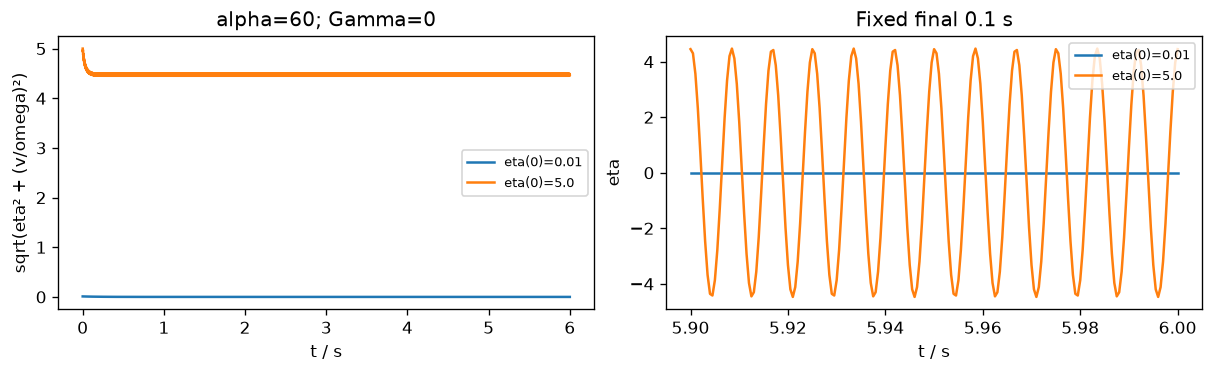

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
for initial, state in deterministic_paths.items():
    time = OUTPUT_DT * np.arange(len(state))
    radius = np.linalg.norm(state, axis=1)
    axes[0].plot(time, radius, label=f"eta(0)={initial[0]}")
    keep = time >= 5.9
    axes[1].plot(time[keep], state[keep, 0], label=f"eta(0)={initial[0]}")
axes[0].set(
    xlabel="t / s", ylabel="sqrt(eta² + (v/omega)²)", title="alpha=60; Gamma=0"
)
axes[1].set(xlabel="t / s", ylabel="eta", title="Fixed final 0.1 s")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

**Figure:** deterministic initial-state diagnostic at α=60, subcritical signs.
**Observation:** a small start approaches the origin while a large start retains
an oscillatory radius; the executed table gives their final RMS values.
**Scientific meaning:** the finite integrations support two attracting outcomes
from these starts, consistent with the averaged subcritical basin structure,
without establishing noise-induced switching or a global basin map.
**Reproduction status:** diagnostic only; this is not Fig. 5 or 7.

### 3.2 Matched-noise time-step study: 100, 50 and 25 μs

For each α=52,50,49 and both sign configurations, generate fine linear
stochastic integrals once; aggregate them using ζ_coarse=F_fine ζ₁+ζ₂ (and the
corresponding four-step composition). Thus coarse and fine paths share the same
Brownian stochastic convolutions, rather than unrelated seeds. Two Gaussian
coordinates describe the exact integrated response of **one** velocity-noise
source; they do not add a second physical noise source to dx.

Use 3 s and compare the final 2 s at common 0.5 ms output times. Above/at the
linear Hopf condition start at the origin; for the nonlinear-resolution check
at 49 start at η=5 (subcritical) or 0.8 (supercritical), v=0. These are deliberate
accuracy tests, separate from the origin-start baseline below. Compare RMS,
path error, distributions and Welch peak frequency; frequency resolution is
reported, not interpreted as a precise eigenfrequency estimate.

In [10]:
def peak_frequency(values, dt=OUTPUT_DT):
    frequencies, power = welch(
        values, fs=1 / dt, nperseg=min(4096, len(values)), detrend="constant"
    )
    index = 1 + np.argmax(power[1:])
    return float(frequencies[index]), frequencies, power


time_step_results, time_step_rows = {}, []
for kind, (name, configuration) in enumerate(CONFIGS.items()):
    for alpha in (52, 50, 49):
        fine_h = 2.5e-5
        noise = linear_innovations(
            alpha, fine_h, round(3 / fine_h), rng_for(2, alpha, kind=kind)
        )
        fine_flow = linear_step(alpha, fine_h)[0]
        initial = (
            (5.0 if name == "subcritical" else 0.8, 0.0)
            if alpha == 49
            else (0, 0)
        )
        paths = {}
        for factor in (4, 2, 1):
            dt = fine_h * factor
            coupled = aggregate_innovations(noise, fine_flow, factor)
            np.testing.assert_allclose(
                linear_step(alpha, dt)[0],
                np.linalg.matrix_power(fine_flow, factor),
                rtol=1e-12,
                atol=1e-14,
            )
            native = integrate_split(
                alpha, configuration, dt, coupled, initial=initial
            )
            path = native[:: round(OUTPUT_DT / dt), 0]
            paths[dt] = path
        reference = paths[fine_h][2000:-1]
        for dt, path in paths.items():
            values = path[2000:-1]
            relative_rms = abs(rms(values) / rms(reference) - 1)
            relative_path = rms(values - reference) / rms(reference)
            frequency, _, _ = peak_frequency(values)
            if np.isclose(dt, H):
                assert relative_rms < 0.02
            assert 110 < frequency < 130
            time_step_rows.append(
                [
                    name,
                    alpha,
                    f"{dt:.7f}",
                    f"{rms(values):.7g}",
                    f"{relative_rms:.4g}",
                    f"{relative_path:.4g}",
                    f"{frequency:.4f}",
                    f"{np.max(np.abs(values)):.5g}",
                ]
            )
        time_step_results[(name, alpha)] = paths
show_table(
    [
        "Signs",
        "alpha",
        "h / s",
        "RMS",
        "Relative RMS vs 25 us",
        "Relative path RMSE",
        "Welch peak / Hz",
        "Max |eta|",
    ],
    time_step_rows,
)
print("Welch resolution for 2 s:", 1 / (4000 * OUTPUT_DT), "Hz")
show_table(
    ["Signs", "alpha", "h / s", "abs(eta) Q50", "Q90", "Q99"],
    [
        [
            name,
            alpha,
            dt,
            *(
                f"{v:.7g}"
                for v in np.quantile(np.abs(path[2000:-1]), [0.5, 0.9, 0.99])
            ),
        ]
        for (name, alpha), paths in time_step_results.items()
        for dt, path in paths.items()
    ],
)

| Signs | alpha | h / s | RMS | Relative RMS vs 25 us | Relative path RMSE | Welch peak / Hz | Max \|eta\| |
|---|---|---|---|---|---|---|---|
| subcritical | 52 | 0.0001000 | 0.003404454 | 1.13e-09 | 1.909e-09 | 120.0000 | 0.0082669 |
| subcritical | 52 | 0.0000500 | 0.003404454 | 4.405e-10 | 9.542e-10 | 120.0000 | 0.0082669 |
| subcritical | 52 | 0.0000250 | 0.003404454 | 0 | 0 | 120.0000 | 0.0082669 |
| subcritical | 50 | 0.0001000 | 0.00270677 | 2.642e-10 | 1.326e-09 | 120.0000 | 0.0079259 |
| subcritical | 50 | 0.0000500 | 0.00270677 | 2.362e-10 | 1.493e-09 | 120.0000 | 0.0079259 |
| subcritical | 50 | 0.0000250 | 0.00270677 | 0 | 0 | 120.0000 | 0.0079259 |
| subcritical | 49 | 0.0001000 | 3.616235 | 1.312e-06 | 0.01497 | 120.0000 | 5.1143 |
| subcritical | 49 | 0.0000500 | 3.616239 | 2.801e-07 | 0.002988 | 120.0000 | 5.1143 |
| subcritical | 49 | 0.0000250 | 3.61624 | 0 | 0 | 120.0000 | 5.1143 |
| supercritical | 52 | 0.0001000 | 0.002583093 | 1.757e-10 | 7.623e-10 | 120.0000 | 0.0054286 |
| supercritical | 52 | 0.0000500 | 0.002583093 | 2.183e-11 | 5.031e-10 | 120.0000 | 0.0054286 |
| supercritical | 52 | 0.0000250 | 0.002583093 | 0 | 0 | 120.0000 | 0.0054286 |
| supercritical | 50 | 0.0001000 | 0.003693334 | 1.346e-09 | 1.845e-09 | 120.0000 | 0.008132 |
| supercritical | 50 | 0.0000500 | 0.003693334 | 2.622e-10 | 6.143e-10 | 120.0000 | 0.008132 |
| supercritical | 50 | 0.0000250 | 0.003693334 | 0 | 0 | 120.0000 | 0.008132 |
| supercritical | 49 | 0.0001000 | 0.4877254 | 6.888e-08 | 1.103e-05 | 120.0000 | 0.71828 |
| supercritical | 49 | 0.0000500 | 0.4877254 | 1.279e-08 | 2.954e-06 | 120.0000 | 0.71828 |
| supercritical | 49 | 0.0000250 | 0.4877254 | 0 | 0 | 120.0000 | 0.71828 |

Welch resolution for 2 s: 0.5 Hz


| Signs | alpha | h / s | abs(eta) Q50 | Q90 | Q99 |
|---|---|---|---|---|---|
| subcritical | 52 | 0.0001 | 0.002975617 | 0.005141693 | 0.00745073 |
| subcritical | 52 | 5e-05 | 0.002975617 | 0.005141693 | 0.00745073 |
| subcritical | 52 | 2.5e-05 | 0.002975617 | 0.005141693 | 0.00745073 |
| subcritical | 50 | 0.0001 | 0.001857396 | 0.004493214 | 0.007155482 |
| subcritical | 50 | 5e-05 | 0.001857396 | 0.004493214 | 0.007155482 |
| subcritical | 50 | 2.5e-05 | 0.001857396 | 0.004493214 | 0.007155482 |
| subcritical | 49 | 0.0001 | 3.632427 | 5.056635 | 5.113333 |
| subcritical | 49 | 5e-05 | 3.619638 | 5.054999 | 5.113441 |
| subcritical | 49 | 2.5e-05 | 3.61652 | 5.055258 | 5.113402 |
| supercritical | 52 | 0.0001 | 0.002258018 | 0.003947964 | 0.004671316 |
| supercritical | 52 | 5e-05 | 0.002258018 | 0.003947964 | 0.004671316 |
| supercritical | 52 | 2.5e-05 | 0.002258018 | 0.003947964 | 0.004671316 |
| supercritical | 50 | 0.0001 | 0.002908429 | 0.005912525 | 0.007677238 |
| supercritical | 50 | 5e-05 | 0.002908429 | 0.005912525 | 0.007677238 |
| supercritical | 50 | 2.5e-05 | 0.002908429 | 0.005912525 | 0.007677238 |
| supercritical | 49 | 0.0001 | 0.4954261 | 0.6777207 | 0.7063903 |
| supercritical | 49 | 5e-05 | 0.4954307 | 0.6777207 | 0.7063902 |
| supercritical | 49 | 2.5e-05 | 0.4954323 | 0.6777208 | 0.7063902 |

**Diagnostic objective:** compare the three matched-noise resolutions at α=49
in the nonlinearly saturated regime for each sign configuration. The fixed final
0.05 s, empirical |η| distributions over the same final 2 s, and unsmoothed
Welch spectra use common output samples; the table also retains the low-amplitude
and marginal α=52/50 cases.

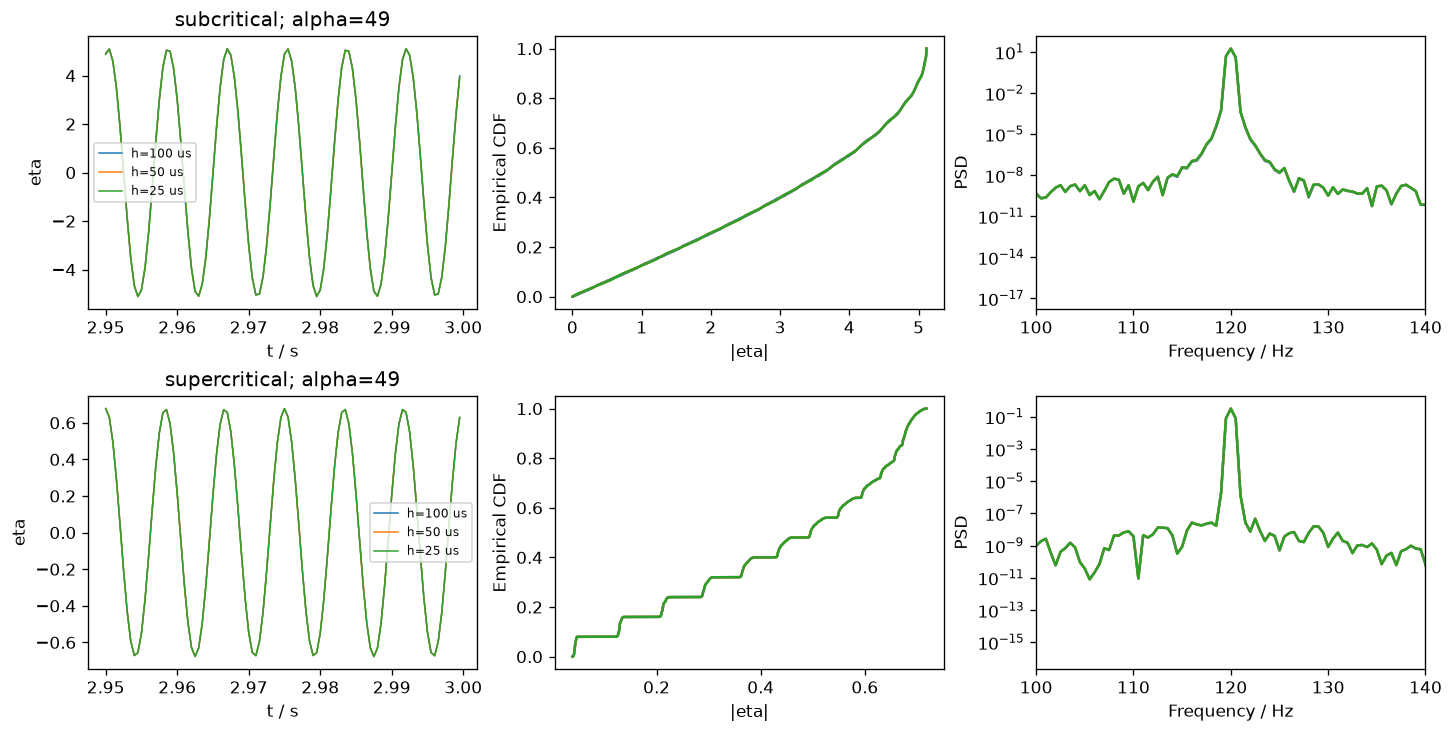

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), layout="constrained")
for row, name in enumerate(CONFIGS):
    paths = time_step_results[(name, 49)]
    for dt, path in paths.items():
        values = path[2000:-1]
        time = OUTPUT_DT * np.arange(len(path))
        shown = (time >= 2.95) & (time < 3)
        axes[row, 0].plot(
            time[shown], path[shown], label=f"h={dt * 1e6:g} us", lw=0.9
        )
        axes[row, 1].plot(
            np.sort(np.abs(values)),
            np.arange(1, len(values) + 1) / len(values),
        )
        _, frequencies, power = peak_frequency(values)
        axes[row, 2].semilogy(frequencies, power)
    axes[row, 0].set(xlabel="t / s", ylabel="eta", title=name + "; alpha=49")
    axes[row, 0].legend(fontsize=7)
    axes[row, 1].set(xlabel="|eta|", ylabel="Empirical CDF")
    axes[row, 2].set(xlabel="Frequency / Hz", ylabel="PSD", xlim=(100, 140))
plt.show()

**Figure:** coupled time-step, amplitude-distribution and frequency diagnostics.
**Observation:** the executed table quantifies common-path changes; the figure
checks whether the saturated waveform, amplitude distribution and near-120-Hz
peak persist at finer resolution. **Scientific meaning:** agreement here tests
discretization at fixed noise, not seed variability or asymptotic stationarity.
**Reproduction status:** diagnostic only; h=50 μs is the declared baseline and
no equation, noise intensity or critical parameter is tuned to match a figure.

## 4. Origin-start Hopf amplitude pilot

For both printed configurations and α=80,60,52,50,49,45, run 33 s from (η,v)=(0,0),
discard 30 s and retain [30,33). Each condition has its own deterministic PCG64
seed keyed by purpose, α, realization and sign configuration. The three-second
record contains 6,000 output samples, exactly four raw 1,500-sample windows.

RMS is calculated in original η units; the detrended version uses a removed
linear trend and is a separate diagnostic. The radius sqrt(η²+(v/ω)²) is an
approximate oscillation amplitude, not an independent complexity measure.
The linear low-amplitude benchmark sqrt[Γ/(2(α−β)ω²)] is available only for
α>β and the linearized model. A finite near-critical record is not assumed to
have reached a stationary amplitude distribution.

In [12]:
records, amplitude_rows = {}, []
started = perf_counter()
for name in CONFIGS:
    for alpha in ALPHAS:
        record = simulate_hopf(alpha, name)
        time, values = retained_signal(record)
        first = round(DISCARD / OUTPUT_DT)
        radius = np.hypot(
            values, record["scaled_velocity"][first : first + len(values)]
        )
        frequency, _, _ = peak_frequency(values)
        linear_rms = (
            np.sqrt(MODEL["Gamma"] / (2 * (alpha - 50) * MODEL["omega"] ** 2))
            if alpha > 50
            else np.nan
        )
        record["retained_rms"] = rms(values)
        records[(name, alpha)] = record
        amplitude_rows.append(
            [
                name,
                alpha,
                f"{rms(values):.7g}",
                f"{rms(detrend(values)):.7g}",
                f"{np.median(radius):.7g}",
                f"{linear_rms:.6g}",
                f"{frequency:.4f}",
                len(values),
            ]
        )
        print(f"{name}, alpha={alpha}: RMS={rms(values):.7g}", flush=True)
show_table(
    [
        "Signs",
        "alpha",
        "eta RMS",
        "Linear-detrended RMS",
        "Median radius",
        "Linear-theory RMS",
        "PSD peak / Hz",
        "Samples",
    ],
    amplitude_rows,
)
print(f"Primary simulation wall time: {perf_counter() - started:.1f} s")

subcritical, alpha=80: RMS=0.0004924013


subcritical, alpha=60: RMS=0.001057246


subcritical, alpha=52: RMS=0.001638005


subcritical, alpha=50: RMS=0.01034776


subcritical, alpha=49: RMS=3.616445


...

supercritical, alpha=50: RMS=0.01520085


supercritical, alpha=49: RMS=0.4738454


supercritical, alpha=45: RMS=1.108324


| Signs | alpha | eta RMS | Linear-detrended RMS | Median radius | Linear-theory RMS | PSD peak / Hz | Samples |
|---|---|---|---|---|---|---|---|
| subcritical | 80 | 0.0004924013 | 0.0004924011 | 0.0005643135 | 0.000541456 | 116.6992 | 6000 |
| subcritical | 60 | 0.001057246 | 0.001057237 | 0.001269276 | 0.000937829 | 119.1406 | 6000 |
| subcritical | 52 | 0.001638005 | 0.001637963 | 0.002020734 | 0.00209705 | 120.1172 | 6000 |
| subcritical | 50 | 0.01034776 | 0.01034776 | 0.01407274 | nan | 120.1172 | 6000 |
| subcritical | 49 | 3.616445 | 3.616441 | 5.114161 | nan | 120.1172 | 6000 |
| subcritical | 45 | 3.727212 | 3.727205 | 5.27001 | nan | 120.1172 | 6000 |
| supercritical | 80 | 0.0005983845 | 0.0005983761 | 0.0007280543 | 0.000541456 | 120.1172 | 6000 |
| supercritical | 60 | 0.001049146 | 0.001049127 | 0.00133454 | 0.000937829 | 119.6289 | 6000 |
| supercritical | 52 | 0.002153218 | 0.002153214 | 0.00288335 | 0.00209705 | 120.1172 | 6000 |
| supercritical | 50 | 0.01520085 | 0.0152008 | 0.02086987 | nan | 120.1172 | 6000 |
| supercritical | 49 | 0.4738454 | 0.4738445 | 0.6701046 | nan | 120.1172 | 6000 |
| supercritical | 45 | 1.108324 | 1.108324 | 1.567419 | nan | 120.1172 | 6000 |

Primary simulation wall time: 12.1 s


**Diagnostic objective:** compare origin-start amplitudes without calling this
Fig. 5 or 7. Each row is a sign configuration; the first two columns show fixed
[30,30.1) low/near-critical and below-threshold traces, and the third shows the
six measured RMS values. The known linear α=50 reference is annotated, with no
critical-point estimator or fitted curve.

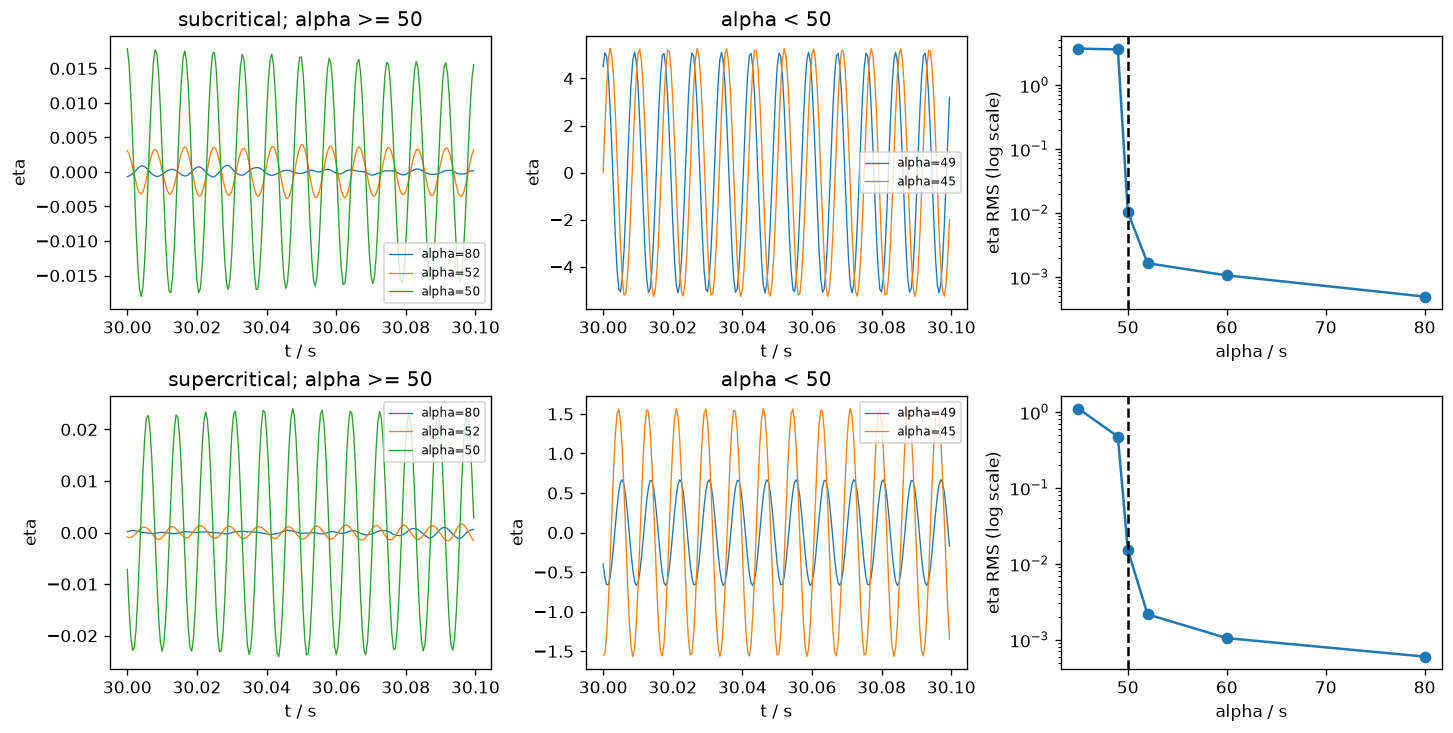

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), layout="constrained")
for row, name in enumerate(CONFIGS):
    for alpha in (80, 52, 50):
        t, x = retained_signal(records[(name, alpha)], length=0.1)
        axes[row, 0].plot(t, x, label=f"alpha={alpha}", lw=0.8)
    for alpha in (49, 45):
        t, x = retained_signal(records[(name, alpha)], length=0.1)
        axes[row, 1].plot(t, x, label=f"alpha={alpha}", lw=0.8)
    axes[row, 2].semilogy(
        ALPHAS, [records[(name, a)]["retained_rms"] for a in ALPHAS], "o-"
    )
    axes[row, 2].axvline(
        50, color="black", ls="--", label="Known linear condition"
    )
    axes[row, 0].set(
        xlabel="t / s", ylabel="eta", title=name + "; alpha >= 50"
    )
    axes[row, 1].set(xlabel="t / s", ylabel="eta", title="alpha < 50")
    axes[row, 2].set(xlabel="alpha / s", ylabel="eta RMS (log scale)")
    for ax in axes[row]:
        ax.legend(fontsize=7) if ax is not axes[row, 2] else None
plt.show()

**Figure:** origin-start amplitude and waveform pilot, both Hopf signs.
**Observation:** the executed values distinguish low stochastic amplitudes above
50 from the sampled sustained oscillations below it; α=50 remains a finite,
noise-driven marginal case. **Scientific meaning:** the comparison concerns
observed amplitudes under a stated start/discard protocol, separate from the
linear Hopf condition and deterministic basin structure. **Reproduction status:**
diagnostic only; an author-like abrupt jump at exactly 50 is not presumed.

### 4.1 Seeds, retained duration, discard and initial conditions

At α=52 and 49 use three independent seed keys for each sign configuration;
replicate zero reuses the primary record. Report sample RMS spread without
claiming an ensemble limit. On each primary path compare non-overlapping
[10,13), [20,23), [30,33) intervals and nested retained lengths 1.5 versus 3 s.
These checks mix finite fluctuations with possible continuing relaxation and
are not independent stationarity tests. At subcritical α=60 compare the origin
and η(0)=5 using the **same stochastic innovations**, changing only the start.

In [14]:
seed_records, seed_rows = {}, []
for name in CONFIGS:
    for alpha in (52, 49):
        values = []
        for replicate in range(3):
            record = (
                records[(name, alpha)]
                if replicate == 0
                else simulate_hopf(alpha, name, replicate=replicate)
            )
            _, signal = retained_signal(record)
            seed_records[(name, alpha, replicate)] = record
            values.append(rms(signal))
            seed_rows.append([name, alpha, replicate, f"{rms(signal):.7g}"])
        print(
            name,
            alpha,
            "RMS mean/sample SD:",
            np.mean(values),
            np.std(values, ddof=1),
        )
show_table(["Signs", "alpha", "Independent realization", "RMS"], seed_rows)
transient_rows = []
for (name, alpha), record in records.items():
    if alpha in (52, 50, 49):
        for start in (10, 20, 30):
            for length in (1.5, 3.0) if start == 30 else (3.0,):
                _, signal = retained_signal(record, start=start, length=length)
                transient_rows.append(
                    [name, alpha, start, length, f"{rms(signal):.7g}"]
                )
show_table(
    ["Signs", "alpha", "Discard / s", "Retained / s", "RMS"], transient_rows
)
noisy_large = simulate_hopf(60, "subcritical", initial=(5.0, 0.0))
show_table(
    ["Subcritical alpha=60 initial eta", "Final RMS"],
    [
        [0.0, records[("subcritical", 60)]["retained_rms"]],
        [5.0, rms(retained_signal(noisy_large)[1])],
    ],
)

subcritical 52 RMS mean/sample SD: 0.0017717659631463125 0.0006094189711626336


subcritical 49 RMS mean/sample SD: 3.61645256109491 7.653043468409459e-05


supercritical 52 RMS mean/sample SD: 0.002013462908525026 0.00020846707474756517


supercritical 49 RMS mean/sample SD: 0.47506482352280394 0.0011075089944642107


| Signs | alpha | Independent realization | RMS |
|---|---|---|---|
| subcritical | 52 | 0 | 0.001638005 |
| subcritical | 52 | 1 | 0.002436954 |
| subcritical | 52 | 2 | 0.001240338 |
| subcritical | 49 | 0 | 3.616445 |
| subcritical | 49 | 1 | 3.61638 |
| subcritical | 49 | 2 | 3.616532 |
| supercritical | 52 | 0 | 0.002153218 |
| supercritical | 52 | 1 | 0.001773851 |
| supercritical | 52 | 2 | 0.00211332 |
| supercritical | 49 | 0 | 0.4738454 |
| supercritical | 49 | 1 | 0.4753408 |
| supercritical | 49 | 2 | 0.4760083 |

| Signs | alpha | Discard / s | Retained / s | RMS |
|---|---|---|---|---|
| subcritical | 52 | 10 | 3.0 | 0.003197843 |
| subcritical | 52 | 20 | 3.0 | 0.001532067 |
| subcritical | 52 | 30 | 1.5 | 0.001606179 |
| subcritical | 52 | 30 | 3.0 | 0.001638005 |
| subcritical | 50 | 10 | 3.0 | 0.01646185 |
| subcritical | 50 | 20 | 3.0 | 0.01615736 |
| subcritical | 50 | 30 | 1.5 | 0.01081829 |
| subcritical | 50 | 30 | 3.0 | 0.01034776 |
| subcritical | 49 | 10 | 3.0 | 2.447523 |
| subcritical | 49 | 20 | 3.0 | 3.616205 |
| subcritical | 49 | 30 | 1.5 | 3.616402 |
| subcritical | 49 | 30 | 3.0 | 3.616445 |
| supercritical | 52 | 10 | 3.0 | 0.001620463 |
| supercritical | 52 | 20 | 3.0 | 0.003253516 |
| supercritical | 52 | 30 | 1.5 | 0.002533052 |
| supercritical | 52 | 30 | 3.0 | 0.002153218 |
| supercritical | 50 | 10 | 3.0 | 0.006452011 |
| supercritical | 50 | 20 | 3.0 | 0.007444164 |
| supercritical | 50 | 30 | 1.5 | 0.01569284 |
| supercritical | 50 | 30 | 3.0 | 0.01520085 |
| supercritical | 49 | 10 | 3.0 | 0.3253128 |
| supercritical | 49 | 20 | 3.0 | 0.4742958 |
| supercritical | 49 | 30 | 1.5 | 0.4739848 |
| supercritical | 49 | 30 | 3.0 | 0.4738454 |

| Subcritical alpha=60 initial eta | Final RMS |
|---|---|
| 0.0 | 0.0010572463600940349 |
| 5.0 | 3.162340988526354 |

The initial-state experiment is finite evidence about two outcomes at one
parameter, not an estimate of switching probabilities or a global stochastic
bistability claim. In particular Γ=10 in the printed acceleration-noise units
produces a very small low-amplitude η scale; neither Γ nor the initial state is
increased just to force a subcritical jump at the paper's reported α=50.

## 5. Delay reconstruction and data-driven working coordinates

For Xᵢ=[xᵢ,xᵢ₊τ,…,xᵢ₊₍ₘ₋₁₎τ], a window of n samples yields
n−(m−1)τ vectors, with no samples borrowed from another window. Estimate τ
using the first local minimum of histogram average mutual information (AMI),
with 16 fixed equal-width bins over each condition's retained range and lags
1–40 output samples. A 32-bin alternative checks histogram sensitivity.
[Fraser and Swinney (1986)](https://doi.org/10.1103/PhysRevA.33.1134)
motivates the minimum rule; this histogram estimator is our numerical choice,
not a claim to reproduce their adaptive algorithm or an author-reported delay.

In [15]:
def delay_embed(values, dimension, delay):
    values = np.asarray(values, dtype=float)
    if (
        values.ndim != 1
        or not np.all(np.isfinite(values))
        or not isinstance(dimension, (int, np.integer))
        or dimension < 1
        or not isinstance(delay, (int, np.integer))
        or delay < 1
    ):
        raise ValueError(
            "Use a finite scalar series and positive integer m/tau."
        )
    count = len(values) - (dimension - 1) * delay
    if count < 1:
        raise ValueError("Insufficient samples for the requested embedding.")
    return values[np.arange(count)[:, None] + delay * np.arange(dimension)]


def histogram_information(counts):
    counts = np.asarray(counts, dtype=float)
    if (
        counts.ndim != 2
        or not np.all(np.isfinite(counts))
        or np.any(counts < 0)
        or counts.sum() <= 0
    ):
        raise ValueError("Provide a nonempty nonnegative joint histogram.")
    joint = counts / counts.sum()
    independent = joint.sum(axis=1)[:, None] * joint.sum(axis=0)[None, :]
    keep = joint > 0
    return float(np.sum(joint[keep] * np.log(joint[keep] / independent[keep])))


def ami_curve(values, max_lag=40, bins=16):
    values = np.asarray(values, dtype=float)
    if len(values) <= max_lag or not np.all(np.isfinite(values)):
        raise ValueError("AMI lags require a longer finite signal.")
    edges = np.histogram_bin_edges(values, bins=bins)
    return np.array(
        [
            histogram_information(
                np.histogram2d(
                    values[:-lag], values[lag:], bins=(edges, edges)
                )[0]
            )
            for lag in range(1, max_lag + 1)
        ]
    )


def first_ami_minimum(curve):
    indices = np.flatnonzero(
        (curve[1:-1] < curve[:-2]) & (curve[1:-1] <= curve[2:])
    )
    return int(indices[0] + 2) if indices.size else None


embedded = delay_embed(np.arange(10), 3, 2)
np.testing.assert_array_equal(
    embedded,
    np.array(
        [[0, 2, 4], [1, 3, 5], [2, 4, 6], [3, 5, 7], [4, 6, 8], [5, 7, 9]]
    ),
)
np.testing.assert_allclose(histogram_information(np.ones((2, 2))), 0)
np.testing.assert_allclose(histogram_information(np.eye(2)), np.log(2))
assert first_ami_minimum(np.array([3, 2, 1, 2, 3])) == 3
assert first_ami_minimum(np.zeros(10)) is None
assert np.all(ami_curve(np.ones(100), max_lag=10) == 0)
print(
    "Embedding ordering, vector count, AMI entropy and minimum tests passed."
)

Embedding ordering, vector count, AMI entropy and minimum tests passed.


### 5.1 Cao E1/E2, including temporal and duplicate-neighbor safeguards

Use [Cao (1997), Eqs. (1–5)](https://doi.org/10.1016/S0167-2789(97)00118-8).
For each dimension d find the nearest **nonidentical** delay vector in the
maximum norm; use that same neighbor when extending to d+1. E(d) averages the
extended/base distance ratio; E*(d) averages the added-coordinate separation.
E1(d)=E(d+1)/E(d) and E2(d)=E*(d+1)/E*(d). Constant duplicates with no eligible
neighbor remain undefined. A brute-force distance implementation verifies the
KD-tree calculation below on a small random sequence.

Select a *working* m from the first three E1 values whose consecutive changes
are <0.05 and whose first value exceeds 0.8; set m=d₀+1. If no such plateau
appears through d=8, use **m=6 with an explicit unresolved flag**, not an estimated
minimum. The added temporal exclusion |i−j|>17 samples is our one-period
safeguard, not an author specification. Show E2, but do not use it as a proof of
determinism for a continuously noise-driven oscillator. A finite E1 plateau
need not certify a finite-dimensional stochastic attractor.

In [16]:
def cao_statistics(values, delay, *, max_dimension=8, theiler=17):
    values = np.asarray(values, dtype=float)
    e, estar, counts = [], [], []
    for dimension in range(1, max_dimension + 2):
        extended = delay_embed(values, dimension + 1, delay)
        points = extended[:, :-1]
        count = len(points)
        if count <= 2 * theiler + 2:
            raise ValueError(
                "Too few candidate vectors for temporal exclusion."
            )
        tree = cKDTree(points)
        k = min(count, 2 * theiler + 3)
        while True:
            distances, neighbors = tree.query(points, k=k, p=np.inf, workers=1)
            allowed = np.abs(neighbors - np.arange(count)[:, None]) > theiler
            allowed &= (distances > 0) & np.isfinite(distances)
            found = allowed.any(axis=1)
            if found.all() or k == count:
                break
            k = min(count, 2 * k)
        positions = allowed.argmax(axis=1)
        selected = neighbors[np.arange(count), positions]
        base = distances[np.arange(count), positions]
        added = np.abs(extended[:, -1] - extended[selected, -1])
        e.append(
            float(np.mean(np.maximum(base[found], added[found]) / base[found]))
            if found.any()
            else np.nan
        )
        estar.append(float(np.mean(added[found])) if found.any() else np.nan)
        counts.append(int(found.sum()))
    e, estar = np.asarray(e), np.asarray(estar)
    with np.errstate(divide="ignore", invalid="ignore"):
        e1, e2 = e[1:] / e[:-1], estar[1:] / estar[:-1]
    return {"E": e, "Estar": estar, "E1": e1, "E2": e2, "valid": counts}


def working_dimension(e1):
    for index in range(len(e1) - 2):
        part = e1[index : index + 3]
        if (
            np.all(np.isfinite(part))
            and part[0] > 0.8
            and np.all(np.abs(np.diff(part)) < 0.05)
        ):
            return index + 2, "estimated plateau (working m)"
    return 6, "unresolved; declared m=6 fallback"

In [17]:
synthetic = rng_for(4, 52).normal(size=120)
checked = cao_statistics(synthetic, 2, max_dimension=3, theiler=2)
brute_e, brute_star = [], []
for dimension in range(1, 5):
    extended = delay_embed(synthetic, dimension + 1, 2)
    points = extended[:, :-1]
    distances = cdist(points, points, metric="chebyshev")
    disallowed = (
        np.abs(np.arange(len(points))[:, None] - np.arange(len(points))) <= 2
    )
    distances[disallowed | (distances == 0)] = np.inf
    neighbors = np.argmin(distances, axis=1)
    base = distances[np.arange(len(points)), neighbors]
    added = np.abs(extended[:, -1] - extended[neighbors, -1])
    brute_e.append(np.mean(np.maximum(base, added) / base))
    brute_star.append(np.mean(added))
np.testing.assert_allclose(checked["E"], brute_e, rtol=1e-13)
np.testing.assert_allclose(checked["Estar"], brute_star, rtol=1e-13)
constant = cao_statistics(np.ones(100), 1, max_dimension=2, theiler=2)
assert np.all(np.isnan(constant["E1"])) and constant["valid"] == [0, 0, 0]
print("Cao matches exhaustive search; duplicate-only cases are undefined.")

Cao matches exhaustive search; duplicate-only cases are undefined.


### 5.2 Estimate embeddings across low, near-critical and oscillatory records

Use the first 3,000 retained samples of each α=80,52,49 record, separately for
both sign configurations. AMI and Cao fitting is in-sample and does not establish
predictive validity. The selected pair is held fixed across that condition's
four RQA windows; no one dimension/delay is silently imposed on every regime.
Changes in these choices can themselves change RQA, so a common m=3,τ=4
alternative will be reported separately before a future curve reproduction.

In [18]:
PILOT_ALPHAS = (80, 52, 49)
embedding_results, embedding_rows = {}, []
for name in CONFIGS:
    for alpha in PILOT_ALPHAS:
        _, signal = retained_signal(records[(name, alpha)])
        values = signal[:3000]
        values = (values - values.mean()) / values.std(ddof=0)
        ami = ami_curve(values)
        delay = first_ami_minimum(ami)
        status = "estimated AMI minimum"
        if delay is None:
            delay = 4
            status = "no AMI minimum; declared quarter-period fallback"
        alternative_delay = first_ami_minimum(ami_curve(values, bins=32))
        cao = cao_statistics(values, delay)
        dimension, dimension_status = working_dimension(cao["E1"])
        embedding_results[(name, alpha)] = {
            "tau": delay,
            "m": dimension,
            "ami": ami,
            "cao": cao,
            "delay_status": status,
            "dimension_status": dimension_status,
        }
        embedding_rows.append(
            [
                name,
                alpha,
                delay,
                f"{delay * OUTPUT_DT:.6f}",
                alternative_delay,
                dimension,
                status,
                dimension_status,
                min(cao["valid"]),
            ]
        )
show_table(
    [
        "Signs",
        "alpha",
        "tau (16 bins)",
        "Delay / s",
        "tau (32 bins)",
        "Working m",
        "Delay status",
        "Dimension status",
        "Min valid NN count",
    ],
    embedding_rows,
)

| Signs | alpha | tau (16 bins) | Delay / s | tau (32 bins) | Working m | Delay status | Dimension status | Min valid NN count |
|---|---|---|---|---|---|---|---|---|
| subcritical | 80 | 4 | 0.002000 | 4 | 7 | estimated AMI minimum | estimated plateau (working m) | 2964 |
| subcritical | 52 | 4 | 0.002000 | 4 | 6 | estimated AMI minimum | estimated plateau (working m) | 2964 |
| subcritical | 49 | 4 | 0.002000 | 2 | 3 | estimated AMI minimum | estimated plateau (working m) | 2964 |
| supercritical | 80 | 4 | 0.002000 | 4 | 6 | estimated AMI minimum | unresolved; declared m=6 fallback | 2964 |
| supercritical | 52 | 4 | 0.002000 | 4 | 6 | estimated AMI minimum | estimated plateau (working m) | 2964 |
| supercritical | 49 | 3 | 0.001500 | 2 | 4 | estimated AMI minimum | estimated plateau (working m) | 2973 |

**Diagnostic objective:** show the measured AMI and Cao ratios for each pilot
condition. The left panels mark the selected AMI minima; E1 and E2 retain their
full d=1,…,8 range. Curves are working-coordinate diagnostics rather than
independent attractor-dimension measurements, especially with continuous noise.

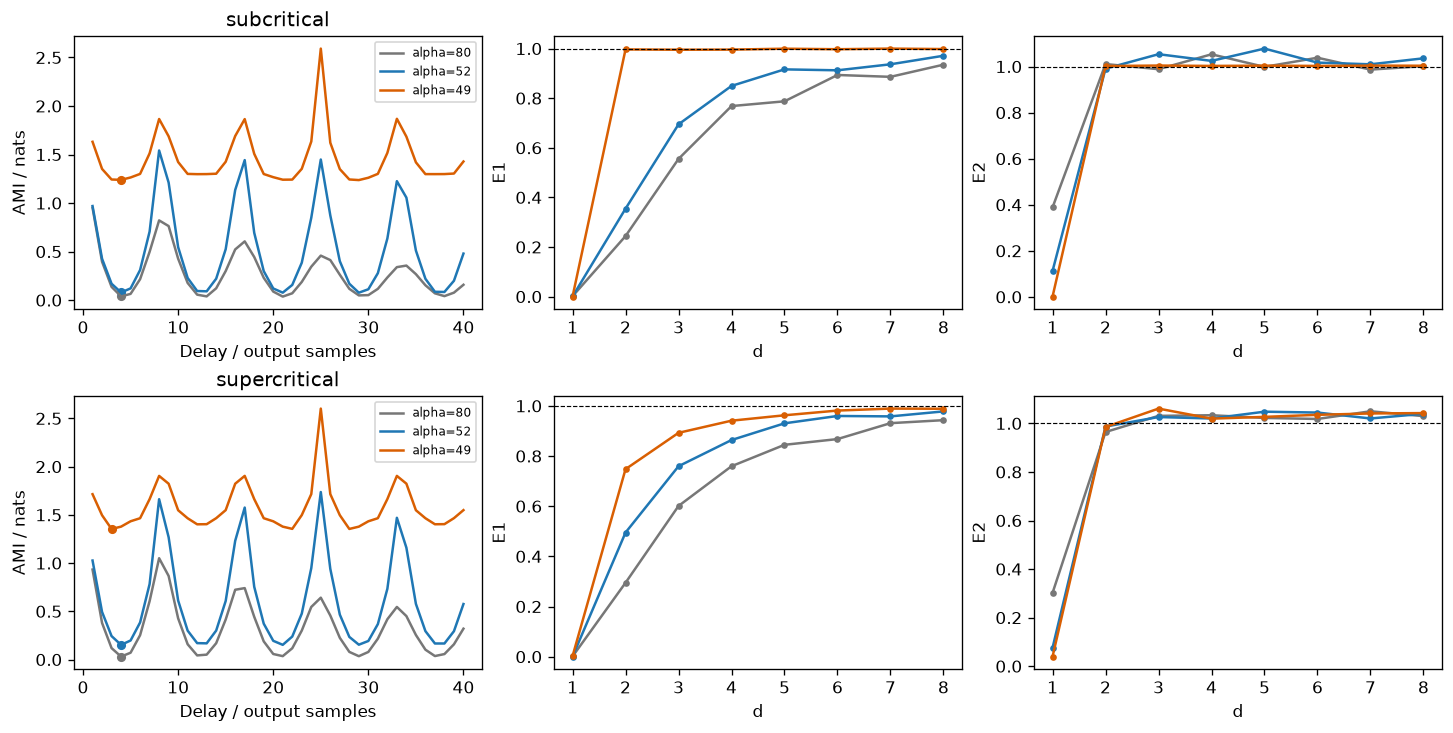

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), layout="constrained")
for row, name in enumerate(CONFIGS):
    for alpha in PILOT_ALPHAS:
        estimate = embedding_results[(name, alpha)]
        color = {80: "#777777", 52: "#1f77b4", 49: "#d95f02"}[alpha]
        axes[row, 0].plot(
            np.arange(1, 41),
            estimate["ami"],
            label=f"alpha={alpha}",
            color=color,
        )
        tau = estimate["tau"]
        axes[row, 0].scatter(
            [tau], [estimate["ami"][tau - 1]], s=20, color=color
        )
        for column, key in ((1, "E1"), (2, "E2")):
            axes[row, column].plot(
                np.arange(1, 9), estimate["cao"][key], "o-", ms=3, color=color
            )
    axes[row, 0].set(
        xlabel="Delay / output samples", ylabel="AMI / nats", title=name
    )
    axes[row, 0].legend(fontsize=7)
    for column, key in ((1, "E1"), (2, "E2")):
        axes[row, column].axhline(1, color="black", ls="--", lw=0.7)
        axes[row, column].set(xlabel="d", ylabel=key)
plt.show()

**Figure:** AMI and Cao working-embedding diagnostics.
**Observation:** the table records every selected delay/dimension, alternative
bin-count delay and any unresolved status; the curves expose the plateau rule.
**Scientific meaning:** finite noisy records and correlated neighbors can alter
these estimates, so coordinate changes must be separated from dynamical changes.
**Reproduction status:** diagnostic only; these are not embedding values reported
by Jella et al., and E2 does not certify chaos or a noise-free attractor here.

## 6. Recurrence matrices: fixed RR and fixed ε remain separate

Use Euclidean distances in the embedded scalar-z-scored window. Calibrate the
quantitative threshold to the **closest attainable RR=0.05**, counting all N²
ordered pairs including the N zero self-distances. Each upper-triangle distance
has weight two. Preserve equal-distance ties, with smaller ε winning an equal
absolute RR error; never split a tie or replace RR=0.05 with ε=0.05. The minimum
achievable RR may exceed 5% for small N or duplicates, and is reported explicitly.
A separate fixed-ε option illustrates a geometric radius in normalized units.

Scalar normalization is uniform across all delayed coordinates. For fixed RR,
a common positive scalar rescaling leaves the distance ordering invariant;
independent coordinate normalizations or changing m/τ need not do so. N is the
number of **embedded** vectors, not the raw 1,500 samples; the explicit
1,600-vector guard bounds dense-matrix memory without subsampling.

In [20]:
def embedded_distances(points):
    points = np.asarray(points, dtype=float)
    if (
        points.ndim != 2
        or not 2 <= len(points) <= MAX_VECTORS
        or not np.all(np.isfinite(points))
    ):
        raise ValueError("Provide 2..1600 finite embedded vectors.")
    return pdist(points, metric="euclidean")


def fixed_rr_plot(points, target=TARGET_RR, *, calibrate_diagonal=True):
    if not 0 <= target <= 1:
        raise ValueError("Target recurrence rate must be in [0,1].")
    distances = embedded_distances(points)
    count = len(points)
    values, multiplicities = np.unique(distances, return_counts=True)
    if values[0] > 0:
        values = np.r_[0.0, values]
        multiplicities = np.r_[0, multiplicities]
    base = count if calibrate_diagonal else 0
    denominator = count**2 if calibrate_diagonal else count * (count - 1)
    rates = (base + 2 * np.cumsum(multiplicities)) / denominator
    selected = int(np.argmin(np.abs(rates - target)))
    epsilon = float(values[selected])
    matrix = squareform(distances) <= epsilon
    actual = (
        matrix.sum() if calibrate_diagonal else matrix.sum() - count
    ) / denominator
    return matrix, {
        "epsilon": epsilon,
        "target": target,
        "calibration_rr": float(actual),
        "rr_error": float(actual - target),
        "minimum_rr": float(rates[0]),
        "N": count,
    }


def fixed_epsilon_plot(points, epsilon):
    if not np.isfinite(epsilon) or epsilon < 0:
        raise ValueError("Use a finite nonnegative distance threshold.")
    return squareform(embedded_distances(points)) <= epsilon


def normalize_scalar(values):
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or not np.all(np.isfinite(values)):
        raise ValueError("Provide a finite scalar window.")
    scale = values.std(ddof=0)
    return (
        (values - values.mean()) / scale
        if scale > 0
        else values - values.mean()
    )

In [21]:
points = np.array([[0, 0], [1, 0], [1, 1]])
np.testing.assert_allclose(
    squareform(embedded_distances(points)),
    [[0, 1, np.sqrt(2)], [1, 0, 1], [np.sqrt(2), 1, 0]],
)
inclusive = fixed_epsilon_plot(points, 1)
np.testing.assert_array_equal(inclusive, [[1, 1, 0], [1, 1, 1], [0, 1, 1]])
assert np.all(inclusive == inclusive.T) and np.all(np.diag(inclusive))
rr_matrix, rr_info = fixed_rr_plot(points, 7 / 9)
assert rr_info["epsilon"] == 1 and rr_info["calibration_rr"] == 7 / 9
constant_matrix, constant_info = fixed_rr_plot(np.ones((10, 2)))
assert constant_info["epsilon"] == 0 and constant_info["minimum_rr"] == 1
assert constant_matrix.all()
small_matrix, small_info = fixed_rr_plot(np.arange(10)[:, None])
assert small_info["minimum_rr"] == 0.1 and small_matrix.mean() == 0.1
random_points = rng_for(5, 52).normal(size=(100, 3))
first, first_info = fixed_rr_plot(random_points)
scaled, scaled_info = fixed_rr_plot(7 * random_points + 20)
np.testing.assert_array_equal(first, scaled)
assert abs(first.mean() - TARGET_RR) <= 1 / len(first) ** 2 + 1e-15
print("RP distances, thresholds, ties and scalar invariance passed.")

RP distances, thresholds, ties and scalar invariance passed.


## 7. RQA definitions and declared line conventions

| Quantity | Implementation |
|---|---|
| RR | sum(R)/N², including self-recurrence |
| DET | Points in off-LOI diagonal runs l≥2 divided by points in all off-LOI diagonal runs l≥1 |
| L | Mean length among off-LOI diagonal runs l≥2 |
| Entr | Natural-log Shannon entropy of the normalized eligible l≥2 line-count histogram |
| LAM | Points in black vertical runs v≥2 divided by points in all black vertical runs |
| TT | Mean black vertical run length among v≥2 |
| RT | Mean complete white vertical run length among k≥2 |
| RTE | Natural-log Shannon entropy of the normalized eligible k≥2 white-line histogram |

LOI denotes the line of identity. Exclude it **only from diagonal statistics**;
retain it when computing RR and vertical lines so removing self-points does not
manufacture new white gaps. There is no other RQA Theiler exclusion. Black runs
include observed boundary-truncated lines. White runs require recurrence at both
ends; a gap between recurrent indices r<s has k=s−r−1 white cells, not return
lag s−r. Censored leading/trailing whites are excluded from the primary estimate.

A zero numerator with a positive DET/LAM denominator gives zero; no eligible
line makes a mean or entropy NaN. Entropy probabilities sum to one **over eligible
lines**. The article's total-line wording and boundary/diagonal implementation
are ambiguous, so this is an explicit conditional-entropy convention; no division
by log N or by a maximum line length is added to match a published value.
All entropies are in nats; line lengths are in sample units (0.5 ms coarse pilot; 0.1 ms refined baseline).

In [22]:
def black_runs(values):
    values = np.asarray(values, dtype=bool)
    changes = np.diff(np.r_[False, values, False].astype(np.int8))
    return np.flatnonzero(changes == -1) - np.flatnonzero(changes == 1)


def validate_binary(matrix):
    matrix = np.asarray(matrix)
    if (
        matrix.ndim != 2
        or matrix.shape[0] != matrix.shape[1]
        or matrix.shape[0] < 1
        or not np.all((matrix == 0) | (matrix == 1))
    ):
        raise ValueError("Provide a nonempty square binary matrix.")
    return matrix.astype(bool, copy=False)


def extract_lines(matrix, *, include_loi=False, white_boundary=False):
    matrix = validate_binary(matrix)
    count = len(matrix)
    diagonal = [
        black_runs(np.diagonal(matrix, offset))
        for offset in range(1 - count, count)
        if offset != 0 or include_loi
    ]
    black = [black_runs(column) for column in matrix.T]
    white = []
    for column in matrix.T:
        if white_boundary:
            gaps = black_runs(~column)
        else:
            recurrent = np.flatnonzero(column)
            gaps = np.diff(recurrent) - 1
            gaps = gaps[gaps > 0]
        white.append(gaps)
    return {
        "diagonal": np.concatenate(diagonal)
        if diagonal
        else np.array([], int),
        "vertical": np.concatenate(black),
        "white": np.concatenate(white),
    }


def eligible_line_summary(lengths, minimum=LINE_MIN):
    lengths = np.asarray(lengths, dtype=int)
    eligible = lengths[lengths >= minimum]
    fraction = (
        float(eligible.sum() / lengths.sum()) if lengths.sum() > 0 else np.nan
    )
    if not len(eligible):
        return fraction, np.nan, np.nan
    _, counts = np.unique(eligible, return_counts=True)
    probabilities = counts / counts.sum()
    entropy = float(-np.sum(probabilities * np.log(probabilities)))
    return fraction, float(eligible.mean()), entropy


def rqa_statistics(matrix, *, include_loi=False, white_boundary=False):
    matrix = validate_binary(matrix)
    lines = extract_lines(
        matrix, include_loi=include_loi, white_boundary=white_boundary
    )
    det, length, entropy = eligible_line_summary(lines["diagonal"])
    lam, trapping, _ = eligible_line_summary(lines["vertical"])
    _, recurrence, rte = eligible_line_summary(lines["white"])
    return dict(
        zip(
            METRICS,
            (
                float(matrix.mean()),
                det,
                length,
                entropy,
                lam,
                trapping,
                recurrence,
                rte,
            ),
            strict=True,
        )
    )

### 7.1 Hand-counted matrices, undefined cases and independent line tracer

The first categorical sequence forms four 2×2 blocks plus repeated-state blocks.
Its off-LOI diagonals have 12 singletons and two length-2 lines; black verticals
have twelve length-2 lines; complete whites have four length-2 lines. Additional
sequences give a nonzero diagonal entropy ln2 and white entropy ln2. Identity,
all-black, all-white and boundary-truncation cases expose denominator policies.
A slow cell-by-cell tracer, independent of padded-run extraction, then checks
all line histograms on 18 small random symmetric binary matrices.

In [23]:
manual_labels = np.array([0, 0, 1, 1, 0, 0, 2, 2])
manual = manual_labels[:, None] == manual_labels[None, :]
manual_lines = extract_lines(manual)
np.testing.assert_array_equal(
    np.sort(manual_lines["diagonal"]), [1] * 12 + [2] * 2
)
np.testing.assert_array_equal(manual_lines["vertical"], [2] * 12)
np.testing.assert_array_equal(manual_lines["white"], [2] * 4)
manual_expected = [3 / 8, 1 / 4, 2, 0, 1, 2, 2, 0]
np.testing.assert_allclose(
    list(rqa_statistics(manual).values()), manual_expected
)
period_two = np.tile([0, 1], 3)
period_two = period_two[:, None] == period_two[None, :]
np.testing.assert_allclose(
    [rqa_statistics(period_two)[k] for k in ("DET", "L", "Entr")],
    [1, 3, np.log(2)],
)
white_labels = np.array([0, 1, 2, 0, 3, 4, 5, 0])
white_example = white_labels[:, None] == white_labels[None, :]
white_lengths = extract_lines(white_example)["white"]
np.testing.assert_array_equal(np.sort(white_lengths), [2] * 3 + [3] * 3)
np.testing.assert_allclose(
    [rqa_statistics(white_example)[k] for k in ("RT", "RTE")], [2.5, np.log(2)]
)
identity = rqa_statistics(np.eye(6, dtype=bool))
assert identity["RR"] == 1 / 6 and identity["LAM"] == 0
assert all(
    np.isnan(identity[k]) for k in ("DET", "L", "Entr", "TT", "RT", "RTE")
)
all_black = rqa_statistics(np.ones((4, 4), dtype=bool))
np.testing.assert_allclose(
    [all_black[k] for k in ("RR", "DET", "L", "Entr", "LAM", "TT")],
    [1, 5 / 6, 2.5, np.log(2), 1, 4],
)
assert np.isnan(all_black["RT"]) and np.isnan(all_black["RTE"])
empty = rqa_statistics(np.zeros((4, 4), dtype=bool))
assert empty["RR"] == 0 and all(np.isnan(empty[k]) for k in METRICS[1:])
boundary = rqa_statistics(np.eye(6, dtype=bool), white_boundary=True)
np.testing.assert_allclose([boundary["RT"], boundary["RTE"]], [3.5, np.log(4)])
print("Eight RQA measures, exact histograms and degenerate cases passed.")

Eight RQA measures, exact histograms and degenerate cases passed.


In [24]:
def trace_line_histogram(
    matrix, direction, value, *, complete=False, exclude_loi=False
):
    count = len(matrix)
    di, dj = direction
    lengths = []
    for i in range(count):
        for j in range(count):
            if (exclude_loi and i == j) or matrix[i, j] != value:
                continue
            previous_i, previous_j = i - di, j - dj
            previous_inside = (
                0 <= previous_i < count and 0 <= previous_j < count
            )
            if previous_inside and matrix[previous_i, previous_j] == value:
                continue
            a, b, length = i, j, 0
            while 0 <= a < count and 0 <= b < count and matrix[a, b] == value:
                length += 1
                a, b = a + di, b + dj
            if complete and not (
                previous_inside and 0 <= a < count and 0 <= b < count
            ):
                continue
            lengths.append(length)
    return np.bincount(lengths, minlength=count + 1)


random_validation = rng_for(6, 52)
for count in range(3, 9):
    for _ in range(3):
        upper = np.triu(random_validation.random((count, count)) < 0.3, 1)
        matrix = upper | upper.T | np.eye(count, dtype=bool)
        extracted = extract_lines(matrix)
        references = {
            "diagonal": trace_line_histogram(
                matrix, (1, 1), True, exclude_loi=True
            ),
            "vertical": trace_line_histogram(matrix, (1, 0), True),
            "white": trace_line_histogram(
                matrix, (1, 0), False, complete=True
            ),
        }
        for key, lengths in extracted.items():
            np.testing.assert_array_equal(
                np.bincount(lengths, minlength=count + 1), references[key]
            )
        metrics = rqa_statistics(matrix)
        for key in ("RR", "DET", "LAM"):
            assert np.isnan(metrics[key]) or 0 <= metrics[key] <= 1
        for key in ("L", "Entr", "TT", "RT", "RTE"):
            assert np.isnan(metrics[key]) or metrics[key] >= 0
print("Independent cell tracer matched 18 random-matrix line histograms.")

Independent cell tracer matched 18 random-matrix line histograms.


### 7.2 Limited external implementation check

The [pyunicorn 1.0.0 source](https://github.com/pik-copan/pyunicorn/blob/v1.0.0/src/pyunicorn/timeseries/recurrence_plot.py)
([Donges et al., 2015](https://doi.org/10.1063/1.4934554)) provides a trusted
comparison for aggregation formulas. Eight unmodified pure-Python measure
methods were executed separately on a twelve-state fixture, supplied with line
histograms from the independent cell tracer. Frozen numeric outputs below make
this test reproducible without a network request or an additional dependency.

This checks **aggregation, not the external compiled line-extraction engine**;
no installed pyunicorn package or full external RQA run is claimed. Its 10⁻⁸
denominator regularizer creates tiny differences and can return zeros where
this notebook uses NaN, so only eligible, well-defined fixture measures are
compared. Its own threshold and white-boundary policies are not silently adopted.

In [25]:
REFERENCE_FIXTURE = {
    "version": "pyunicorn 1.0.0 pure-Python aggregation methods",
    "source_sha256": (
        "824314190632f700e47b7b6d0e3a08c2c09809c65edd781e82dbb9c325f95b18"
    ),
    "labels": [0, 0, 1, 0, 0, 2, 1, 1, 0, 3, 1, 0],
    "diagonal": [26, 8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "vertical": [22, 16, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "white": [6, 10, 10, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "expected": [
        0.375,
        0.380952380861678,
        1.9999999974999998,
        1.2500001026442136e-09,
        0.5925925924828532,
        1.99999999875,
        2.49999999875,
        0.6931471807133717,
    ],
}
labels = np.array(REFERENCE_FIXTURE["labels"])
reference_matrix = labels[:, None] == labels[None, :]
reference_lines = extract_lines(reference_matrix)
for key in ("diagonal", "vertical", "white"):
    observed = np.bincount(reference_lines[key], minlength=len(labels) + 1)[1:]
    np.testing.assert_array_equal(observed, REFERENCE_FIXTURE[key])
reference_result = rqa_statistics(reference_matrix)
np.testing.assert_allclose(
    list(reference_result.values()),
    REFERENCE_FIXTURE["expected"],
    rtol=1e-7,
    atol=1e-7,
)
show_table(
    ["Measure", "This notebook", "pyunicorn source aggregation fixture"],
    [
        [key, f"{reference_result[key]:.10g}", f"{expected:.10g}"]
        for key, expected in zip(
            METRICS, REFERENCE_FIXTURE["expected"], strict=True
        )
    ],
)
print("Reference source SHA-256:", REFERENCE_FIXTURE["source_sha256"])

| Measure | This notebook | pyunicorn source aggregation fixture |
|---|---|---|
| RR | 0.375 | 0.375 |
| DET | 0.380952381 | 0.3809523809 |
| L | 2 | 1.999999997 |
| Entr | -0 | 1.250000103e-09 |
| LAM | 0.5925925926 | 0.5925925925 |
| TT | 2 | 1.999999999 |
| RT | 2.5 | 2.499999999 |
| RTE | 0.6931471806 | 0.6931471807 |

Reference source SHA-256: 824314190632f700e47b7b6d0e3a08c2c09809c65edd781e82dbb9c325f95b18


### 7.3 Diagnostic recurrence plots: controlled coordinates, two thresholds

Compare α=80 versus 49 for both sign configurations using the first **512 raw
retained samples**, common display coordinates m=3,τ=4, and scalar z-scores.
Top row uses RR=0.05, bottom row fixed ε=0.5 in those normalized Euclidean
coordinates. These display choices are explicitly separate from the estimated
condition-specific coordinates and full 1,500-sample windows used below.
The paper's 20%-of-attractor-size example concerns experimental Fig. 2; it is not
silently assigned as an author-specified Hopf threshold.

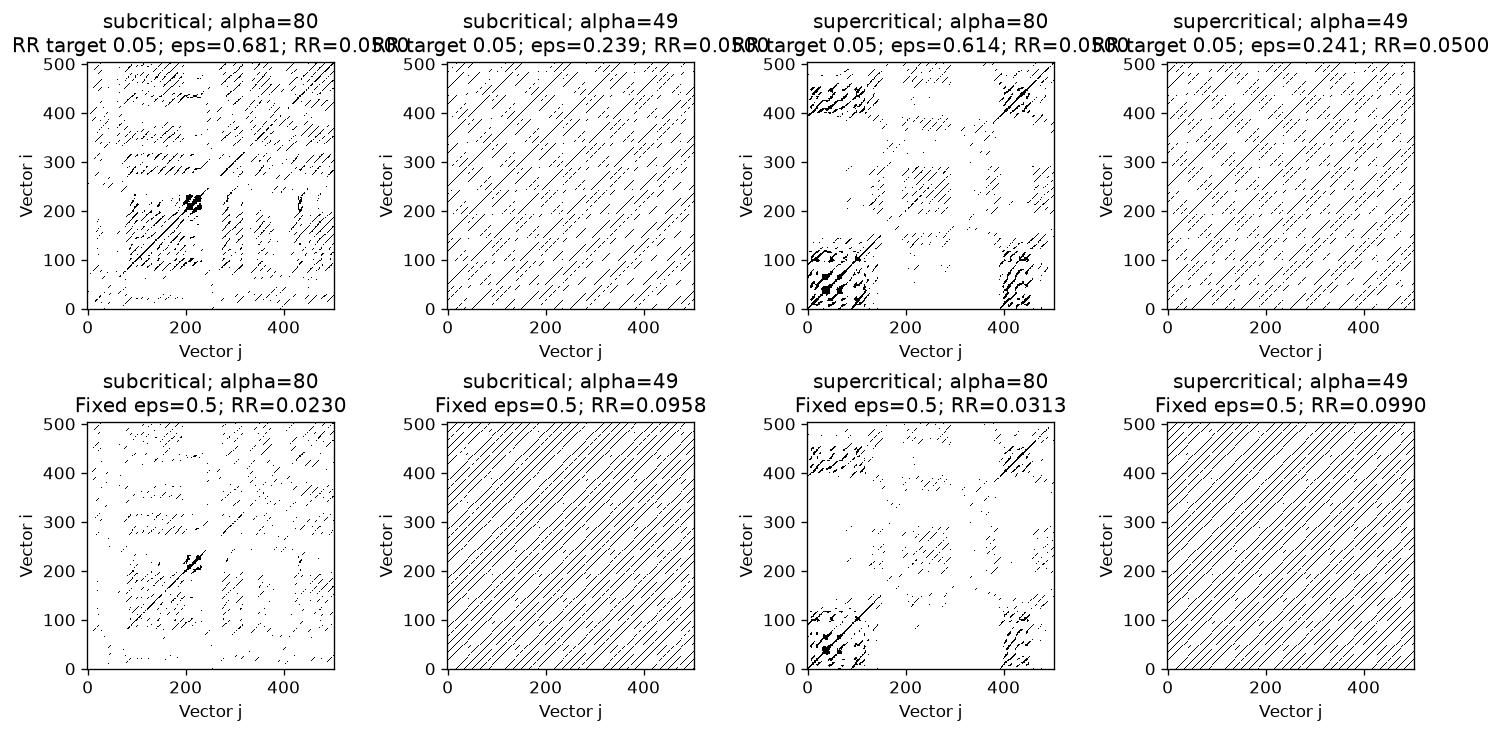

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6), layout="constrained")
for column, (name, alpha) in enumerate(
    (
        ("subcritical", 80),
        ("subcritical", 49),
        ("supercritical", 80),
        ("supercritical", 49),
    )
):
    _, signal = retained_signal(records[(name, alpha)])
    points = delay_embed(normalize_scalar(signal[:512]), 3, 4)
    adaptive, info = fixed_rr_plot(points)
    fixed = fixed_epsilon_plot(points, 0.5)
    for row, matrix in enumerate((adaptive, fixed)):
        axes[row, column].imshow(
            matrix,
            cmap="binary",
            origin="lower",
            interpolation="nearest",
            vmin=0,
            vmax=1,
        )
        label = (
            f"RR target 0.05; eps={info['epsilon']:.3g}"
            if row == 0
            else "Fixed eps=0.5"
        )
        axes[row, column].set(
            title=f"{name}; alpha={alpha}\n{label}; RR={matrix.mean():.4f}",
            xlabel="Vector j",
            ylabel="Vector i",
        )
plt.show()

**Figure:** fixed-RR versus fixed-ε recurrence-structure diagnostic.
**Observation:** the oscillatory records can be examined for coherent diagonal
bands while the low-amplitude noisy records retain less uniform local patterns;
actual RR and distance thresholds are labeled separately.
**Scientific meaning:** controlling density differs from fixing a radius, and
line structure cannot be inferred from recurrence density alone.
**Reproduction status:** diagnostic only; no published Hopf curve is claimed.

## 8. Coarse 2 kHz end-to-end RQA pilot

Each retained 6,000-sample η signal is split into **four non-overlapping raw
windows of 1,500 samples** (0.75 s each), with no partial tail discarded.
Normalize and embed inside each window, then calibrate a new ε to 5% RR for
that window. Fix the condition's previously estimated m/τ across its windows.
No embedded vector crosses a window boundary. Means are unweighted averages of
window measures: any undefined metric in a window propagates to its aggregate,
with all offending indices reported. RMS in the summary refers to the full
retained scalar record, not the arithmetic mean of window RMS values.

In [27]:
def rqa_windows(
    values,
    dimension,
    delay,
    *,
    window=WINDOW,
    calibrate_diagonal=True,
    include_loi=False,
    white_boundary=False,
):
    values = np.asarray(values, dtype=float)
    if (
        values.ndim != 1
        or not np.all(np.isfinite(values))
        or not len(values)
        or len(values) % window
    ):
        raise ValueError(
            "Require finite scalar data and complete raw windows."
        )
    windows = []
    for index, raw in enumerate(values.reshape(-1, window)):
        embedded = delay_embed(normalize_scalar(raw), dimension, delay)
        matrix, info = fixed_rr_plot(
            embedded, calibrate_diagonal=calibrate_diagonal
        )
        metrics = rqa_statistics(
            matrix, include_loi=include_loi, white_boundary=white_boundary
        )
        windows.append(
            {
                **info,
                **metrics,
                "window": index,
                "m": dimension,
                "tau": delay,
                "raw_samples": window,
                "raw_rms": rms(raw),
                "undefined": [
                    k for k in METRICS if not np.isfinite(metrics[k])
                ],
            }
        )
    return windows


def aggregate_rqa(windows):
    if not windows:
        raise ValueError("At least one RQA window is required.")
    means = {key: float(np.mean([w[key] for w in windows])) for key in METRICS}
    invalid = {
        key: [i for i, w in enumerate(windows) if not np.isfinite(w[key])]
        for key in METRICS
    }
    return means, invalid


try:
    rqa_windows(np.arange(1501.0), 3, 4)
except ValueError:
    pass
else:
    raise AssertionError("An incomplete raw window was silently accepted.")
undefined_windows = [{key: 1.0 for key in METRICS} for _ in range(2)]
undefined_windows[1]["RT"] = np.nan
undefined_means, undefined_indices = aggregate_rqa(undefined_windows)
assert np.isnan(undefined_means["RT"]) and undefined_indices["RT"] == [1]
assert undefined_means["DET"] == 1
print("Complete-window enforcement and strict metric aggregation passed.")

Complete-window enforcement and strict metric aggregation passed.


In [28]:
pilot_windows, pilot_summaries, pilot_rows = {}, {}, []
for name in CONFIGS:
    for alpha in PILOT_ALPHAS:
        _, values = retained_signal(records[(name, alpha)])
        estimate = embedding_results[(name, alpha)]
        windows = rqa_windows(values, estimate["m"], estimate["tau"])
        means, invalid = aggregate_rqa(windows)
        pilot_windows[(name, alpha)] = windows
        pilot_summaries[(name, alpha)] = {"mean": means, "invalid": invalid}
        pilot_rows.append(
            [
                name,
                alpha,
                f"{rms(values):.6g}",
                *(f"{means[key]:.6g}" for key in METRICS),
                len(windows),
                sum(len(v) for v in invalid.values()),
            ]
        )
        print(
            name,
            alpha,
            "m/tau:",
            estimate["m"],
            estimate["tau"],
            "; windows:",
            len(windows),
            "; invalid:",
            invalid,
            flush=True,
        )
show_table(
    [
        "Hopf signs",
        "alpha",
        "RMS",
        *METRICS,
        "Windows",
        "Undefined metric/window pairs",
    ],
    pilot_rows,
)

subcritical 80 m/tau: 7 4 ; windows: 4 ; invalid: {'RR': [], 'DET': [], 'L': [], 'Entr': [], 'LAM': [], 'TT': [], 'RT': [], 'RTE': []}


subcritical 52 m/tau: 6 4 ; windows: 4 ; invalid: {'RR': [], 'DET': [], 'L': [], 'Entr': [], 'LAM': [], 'TT': [], 'RT': [], 'RTE': []}


subcritical 49 m/tau: 3 4 ; windows: 4 ; invalid: {'RR': [], 'DET': [], 'L': [], 'Entr': [], 'LAM': [], 'TT': [0, 1, 2, 3], 'RT': [], 'RTE': []}


supercritical 80 m/tau: 6 4 ; windows: 4 ; invalid: {'RR': [], 'DET': [], 'L': [], 'Entr': [], 'LAM': [], 'TT': [], 'RT': [], 'RTE': []}


supercritical 52 m/tau: 6 4 ; windows: 4 ; invalid: {'RR': [], 'DET': [], 'L': [], 'Entr': [], 'LAM': [], 'TT': [], 'RT': [], 'RTE': []}


supercritical 49 m/tau: 4 3 ; windows: 4 ; invalid: {'RR': [], 'DET': [], 'L': [], 'Entr': [], 'LAM': [], 'TT': [0, 1, 2, 3], 'RT': [], 'RTE': []}


| Hopf signs | alpha | RMS | RR | DET | L | Entr | LAM | TT | RT | RTE | Windows | Undefined metric/window pairs |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| subcritical | 80 | 0.000492401 | 0.0499996 | 0.97638 | 10.468 | 2.96197 | 0.885975 | 3.18749 | 43.8585 | 3.6491 | 4 | 0 |
| subcritical | 52 | 0.00163801 | 0.05 | 0.994993 | 30.1492 | 3.90822 | 0.766093 | 2.43103 | 25.5918 | 1.66999 | 4 | 0 |
| subcritical | 49 | 3.61645 | 0.0500004 | 0.997382 | 25.3097 | 2.00054 | 0 | nan | 18.9488 | 0.944638 | 4 | 4 |
| supercritical | 80 | 0.000598384 | 0.05 | 0.980503 | 11.6616 | 3.10847 | 0.84924 | 2.99173 | 39.6345 | 3.31653 | 4 | 0 |
| supercritical | 52 | 0.00215322 | 0.05 | 0.995469 | 35.1816 | 3.91061 | 0.630547 | 2.94144 | 22.0289 | 1.56241 | 4 | 0 |
| supercritical | 49 | 0.473845 | 0.0500004 | 0.999977 | 10.601 | 1.07594 | 0 | nan | 18.9495 | 1.00285 | 4 | 4 |

In [29]:
window_rows = []
for (name, alpha), windows in pilot_windows.items():
    for w in windows:
        window_rows.append(
            [
                name,
                alpha,
                w["window"],
                w["m"],
                w["tau"],
                w["N"],
                f"{w['epsilon']:.6g}",
                f"{w['rr_error']:.3g}",
                *(f"{w[key]:.6g}" for key in METRICS),
                str(w["undefined"]),
            ]
        )
show_table(
    [
        "Signs",
        "alpha",
        "Window",
        "m",
        "tau",
        "N vectors",
        "epsilon",
        "Calibration RR minus target",
        *METRICS,
        "Undefined",
    ],
    window_rows,
)
show_table(
    ["Signs", "alpha", "Metric", "Undefined window indices"],
    [
        [name, alpha, key, str(indices)]
        for (name, alpha), summary in pilot_summaries.items()
        for key, indices in summary["invalid"].items()
        if indices
    ],
)

| Signs | alpha | Window | m | tau | N vectors | epsilon | Calibration RR minus target | RR | DET | L | Entr | LAM | TT | RT | RTE | Undefined |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| subcritical | 80 | 0 | 7 | 4 | 1476 | 1.42238 | -3.67e-07 | 0.0499996 | 0.965305 | 8.57365 | 2.7151 | 0.883005 | 2.98199 | 43.4272 | 3.84175 | [] |
| subcritical | 80 | 1 | 7 | 4 | 1476 | 1.25737 | -3.67e-07 | 0.0499996 | 0.980494 | 10.9109 | 3.03126 | 0.876487 | 3.30063 | 46.0098 | 3.63373 | [] |
| subcritical | 80 | 2 | 7 | 4 | 1476 | 1.2244 | -3.67e-07 | 0.0499996 | 0.980847 | 11.9278 | 3.1088 | 0.871915 | 2.83324 | 38.4063 | 3.24997 | [] |
| subcritical | 80 | 3 | 7 | 4 | 1476 | 1.1927 | -3.67e-07 | 0.0499996 | 0.978874 | 10.4596 | 2.99271 | 0.912493 | 3.63409 | 47.5906 | 3.87095 | [] |
| subcritical | 52 | 0 | 6 | 4 | 1480 | 0.846499 | 0 | 0.05 | 0.996316 | 36.8385 | 4.01371 | 0.771658 | 2.83464 | 19.3524 | 1.59643 | [] |
| subcritical | 52 | 1 | 6 | 4 | 1480 | 0.793148 | 0 | 0.05 | 0.993077 | 23.1133 | 3.7693 | 0.817047 | 2.23161 | 27.9163 | 1.78582 | [] |
| subcritical | 52 | 2 | 6 | 4 | 1480 | 0.836914 | 0 | 0.05 | 0.995816 | 29.22 | 3.9675 | 0.821329 | 2.52207 | 30.0695 | 1.83093 | [] |
| subcritical | 52 | 3 | 6 | 4 | 1480 | 0.802508 | 0 | 0.05 | 0.994761 | 31.4251 | 3.88236 | 0.654337 | 2.13581 | 25.029 | 1.46678 | [] |
| subcritical | 49 | 0 | 3 | 4 | 1492 | 0.255789 | 3.59e-07 | 0.0500004 | 0.997122 | 25.4169 | 1.9964 | 0 | nan | 18.9489 | 0.944674 | ['TT'] |
| subcritical | 49 | 1 | 3 | 4 | 1492 | 0.25624 | 3.59e-07 | 0.0500004 | 0.997705 | 25.2094 | 2.00174 | 0 | nan | 18.9487 | 0.944613 | ['TT'] |
| subcritical | 49 | 2 | 3 | 4 | 1492 | 0.256358 | 3.59e-07 | 0.0500004 | 0.997578 | 25.1483 | 1.99574 | 0 | nan | 18.949 | 0.944623 | ['TT'] |
| subcritical | 49 | 3 | 3 | 4 | 1492 | 0.255993 | 3.59e-07 | 0.0500004 | 0.997122 | 25.4642 | 2.00829 | 0 | nan | 18.9485 | 0.944643 | ['TT'] |
| supercritical | 80 | 0 | 6 | 4 | 1480 | 1.01597 | 0 | 0.05 | 0.983784 | 12.4898 | 3.17308 | 0.859651 | 3.25336 | 40.6318 | 3.24803 | [] |
| supercritical | 80 | 1 | 6 | 4 | 1480 | 1.08652 | 0 | 0.05 | 0.977305 | 10.6161 | 3.02056 | 0.87185 | 2.90794 | 40.6496 | 3.50138 | [] |
| supercritical | 80 | 2 | 6 | 4 | 1480 | 1.14176 | 0 | 0.05 | 0.975046 | 9.75769 | 2.93284 | 0.860126 | 3.06165 | 43.367 | 3.75792 | [] |
| supercritical | 80 | 3 | 6 | 4 | 1480 | 1.00573 | 0 | 0.05 | 0.985876 | 13.7829 | 3.3074 | 0.805332 | 2.74399 | 33.8896 | 2.7588 | [] |
| supercritical | 52 | 0 | 6 | 4 | 1480 | 0.805496 | 0 | 0.05 | 0.997168 | 47.9244 | 3.99909 | 0.665312 | 2.52145 | 18.5815 | 1.37622 | [] |
| supercritical | 52 | 1 | 6 | 4 | 1480 | 0.672298 | 0 | 0.05 | 0.996464 | 39.7262 | 4.00581 | 0.390769 | 2.02474 | 19.9974 | 1.07295 | [] |
| supercritical | 52 | 2 | 6 | 4 | 1480 | 0.780722 | 0 | 0.05 | 0.995002 | 30.3501 | 3.8984 | 0.716965 | 2.09521 | 25.824 | 1.50488 | [] |
| supercritical | 52 | 3 | 6 | 4 | 1480 | 0.723939 | 0 | 0.05 | 0.993243 | 22.7255 | 3.73914 | 0.749142 | 5.12435 | 23.7128 | 2.29557 | [] |
| supercritical | 49 | 0 | 4 | 3 | 1491 | 0.272742 | 4.27e-07 | 0.0500004 | 0.999982 | 11.3217 | 1.2462 | 0 | nan | 18.9532 | 1.02127 | ['TT'] |
| supercritical | 49 | 1 | 4 | 3 | 1491 | 0.273438 | 4.27e-07 | 0.0500004 | 1 | 10.4125 | 1.10873 | 0 | nan | 18.9505 | 1.0019 | ['TT'] |
| supercritical | 49 | 2 | 4 | 3 | 1491 | 0.273488 | 4.27e-07 | 0.0500004 | 0.999927 | 10.4494 | 1.08982 | 0 | nan | 18.9535 | 1.00184 | ['TT'] |
| supercritical | 49 | 3 | 4 | 3 | 1491 | 0.273779 | 4.27e-07 | 0.0500004 | 1 | 10.2203 | 0.85902 | 0 | nan | 18.9409 | 0.986392 | ['TT'] |

| Signs | alpha | Metric | Undefined window indices |
|---|---|---|---|
| subcritical | 49 | TT | [0, 1, 2, 3] |
| supercritical | 49 | TT | [0, 1, 2, 3] |

This is a six-condition numerical pilot, not the full Fig. 5/7 trend or a
reference-point scaling analysis. Fixed RR removes density variation as an
independent signal; it does not guarantee that other RQA values are comparable
across changing embedding dimension, delay, sampling or boundary conventions.
Nearly periodic motion need not have zero measured line entropy because finite
RP edges truncate otherwise coherent lines to different lengths.

### 8.1 Controlled methodological alternatives on the first raw window

For each pilot condition, change **one** choice at a time: include the LOI in
diagonal statistics; include censored boundary white runs; calibrate 5% over
off-diagonal pairs; set m=3 at the estimated τ; or set τ=4 at the estimated m.
Keep the same first 1,500 raw samples and retain every result. Off-diagonal
calibration still reports RR over all N² entries, so its final RR is slightly
above 5%. These tests expose conventions; none is selected to improve figure
agreement. This retains the coarse-pilot reference; the separate sampling audit below establishes the final baseline.

In [30]:
convention_rows = []
for (name, alpha), windows in pilot_windows.items():
    _, values = retained_signal(records[(name, alpha)])
    estimate = embedding_results[(name, alpha)]
    options = (
        ("reference", {}, estimate["m"], estimate["tau"]),
        (
            "LOI in diagonal stats",
            {"include_loi": True},
            estimate["m"],
            estimate["tau"],
        ),
        (
            "boundary whites included",
            {"white_boundary": True},
            estimate["m"],
            estimate["tau"],
        ),
        (
            "off-diagonal RR calibration",
            {"calibrate_diagonal": False},
            estimate["m"],
            estimate["tau"],
        ),
        ("m=3 only", {}, 3, estimate["tau"]),
        ("tau=4 only", {}, estimate["m"], 4),
    )
    for option, changes, dimension, delay in options:
        result = (
            windows[0]
            if option == "reference"
            else rqa_windows(values[:1500], dimension, delay, **changes)[0]
        )
        convention_rows.append(
            [
                name,
                alpha,
                option,
                dimension,
                delay,
                *(f"{result[key]:.6g}" for key in METRICS),
                str(result["undefined"]),
            ]
        )
show_table(
    [
        "Signs",
        "alpha",
        "One methodological choice",
        "m",
        "tau",
        *METRICS,
        "Undefined",
    ],
    convention_rows,
)

| Signs | alpha | One methodological choice | m | tau | RR | DET | L | Entr | LAM | TT | RT | RTE | Undefined |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| subcritical | 80 | reference | 7 | 4 | 0.0499996 | 0.965305 | 8.57365 | 2.7151 | 0.883005 | 2.98199 | 43.4272 | 3.84175 | [] |
| subcritical | 80 | LOI in diagonal stats | 7 | 4 | 0.0499996 | 0.965776 | 8.69493 | 2.71574 | 0.883005 | 2.98199 | 43.4272 | 3.84175 | [] |
| subcritical | 80 | boundary whites included | 7 | 4 | 0.0499996 | 0.965305 | 8.57365 | 2.7151 | 0.883005 | 2.98199 | 44.7856 | 3.95534 | [] |
| subcritical | 80 | off-diagonal RR calibration | 7 | 4 | 0.0506432 | 0.965513 | 8.62607 | 2.72651 | 0.884574 | 2.98913 | 43.0591 | 3.83144 | [] |
| subcritical | 80 | m=3 only | 3 | 4 | 0.0500004 | 0.9413 | 5.65398 | 2.33944 | 0.834157 | 2.79763 | 39.2499 | 3.94214 | [] |
| subcritical | 80 | tau=4 only | 7 | 4 | 0.0499996 | 0.965305 | 8.57365 | 2.7151 | 0.883005 | 2.98199 | 43.4272 | 3.84175 | [] |
| subcritical | 52 | reference | 6 | 4 | 0.05 | 0.996316 | 36.8385 | 4.01371 | 0.771658 | 2.83464 | 19.3524 | 1.59643 | [] |
| subcritical | 52 | LOI in diagonal stats | 6 | 4 | 0.05 | 0.996366 | 37.3322 | 4.01541 | 0.771658 | 2.83464 | 19.3524 | 1.59643 | [] |
| subcritical | 52 | boundary whites included | 6 | 4 | 0.05 | 0.996316 | 36.8385 | 4.01371 | 0.771658 | 2.83464 | 37.1237 | 1.90334 | [] |
| subcritical | 52 | off-diagonal RR calibration | 6 | 4 | 0.0506419 | 0.996236 | 36.9356 | 3.9811 | 0.777203 | 2.84059 | 19.3415 | 1.60033 | [] |
| subcritical | 52 | m=3 only | 3 | 4 | 0.0500004 | 0.989218 | 14.6953 | 2.85682 | 0.755777 | 2.83665 | 20.1028 | 1.70902 | [] |
| subcritical | 52 | tau=4 only | 6 | 4 | 0.05 | 0.996316 | 36.8385 | 4.01371 | 0.771658 | 2.83464 | 19.3524 | 1.59643 | [] |
| subcritical | 49 | reference | 3 | 4 | 0.0500004 | 0.997122 | 25.4169 | 1.9964 | 0 | nan | 18.9489 | 0.944674 | ['TT'] |
| subcritical | 49 | LOI in diagonal stats | 3 | 4 | 0.0500004 | 0.997161 | 25.7573 | 1.99811 | 0 | nan | 18.9489 | 0.944674 | ['TT'] |
| subcritical | 49 | boundary whites included | 3 | 4 | 0.0500004 | 0.997122 | 25.4169 | 1.9964 | 0 | nan | 18.7941 | 1.09558 | ['TT'] |
| subcritical | 49 | off-diagonal RR calibration | 3 | 4 | 0.0506365 | 0.997177 | 26.6364 | 2.00814 | 0 | nan | 18.6995 | 0.938348 | ['TT'] |
| subcritical | 49 | m=3 only | 3 | 4 | 0.0500004 | 0.997122 | 25.4169 | 1.9964 | 0 | nan | 18.9489 | 0.944674 | ['TT'] |
| subcritical | 49 | tau=4 only | 3 | 4 | 0.0500004 | 0.997122 | 25.4169 | 1.9964 | 0 | nan | 18.9489 | 0.944674 | ['TT'] |
| supercritical | 80 | reference | 6 | 4 | 0.05 | 0.983784 | 12.4898 | 3.17308 | 0.859651 | 3.25336 | 40.6318 | 3.24803 | [] |
| supercritical | 80 | LOI in diagonal stats | 6 | 4 | 0.05 | 0.984003 | 12.6622 | 3.17388 | 0.859651 | 3.25336 | 40.6318 | 3.24803 | [] |
| supercritical | 80 | boundary whites included | 6 | 4 | 0.05 | 0.983784 | 12.4898 | 3.17308 | 0.859651 | 3.25336 | 45.7061 | 3.47745 | [] |
| supercritical | 80 | off-diagonal RR calibration | 6 | 4 | 0.0506419 | 0.983901 | 12.6035 | 3.18315 | 0.861737 | 3.25975 | 40.3128 | 3.23907 | [] |
| supercritical | 80 | m=3 only | 3 | 4 | 0.0500004 | 0.971679 | 8.37141 | 2.81048 | 0.835451 | 3.12138 | 38.7152 | 3.35111 | [] |
| supercritical | 80 | tau=4 only | 6 | 4 | 0.05 | 0.983784 | 12.4898 | 3.17308 | 0.859651 | 3.25336 | 40.6318 | 3.24803 | [] |
| supercritical | 52 | reference | 6 | 4 | 0.05 | 0.997168 | 47.9244 | 3.99909 | 0.665312 | 2.52145 | 18.5815 | 1.37622 | [] |
| supercritical | 52 | LOI in diagonal stats | 6 | 4 | 0.05 | 0.997206 | 48.5611 | 4.00119 | 0.665312 | 2.52145 | 18.5815 | 1.37622 | [] |
| supercritical | 52 | boundary whites included | 6 | 4 | 0.05 | 0.997168 | 47.9244 | 3.99909 | 0.665312 | 2.52145 | 31.1484 | 1.68426 | [] |
| supercritical | 52 | off-diagonal RR calibration | 6 | 4 | 0.0506419 | 0.997442 | 47.964 | 4.00733 | 0.673431 | 2.52002 | 18.5219 | 1.37261 | [] |
| supercritical | 52 | m=3 only | 3 | 4 | 0.0500004 | 0.990711 | 15.7396 | 2.68377 | 0.663471 | 2.54102 | 19.1121 | 1.45661 | [] |
| supercritical | 52 | tau=4 only | 6 | 4 | 0.05 | 0.997168 | 47.9244 | 3.99909 | 0.665312 | 2.52145 | 18.5815 | 1.37622 | [] |
| supercritical | 49 | reference | 4 | 3 | 0.0500004 | 0.999982 | 11.3217 | 1.2462 | 0 | nan | 18.9532 | 1.02127 | ['TT'] |
| supercritical | 49 | LOI in diagonal stats | 4 | 3 | 0.0500004 | 0.999982 | 11.4745 | 1.24712 | 0 | nan | 18.9532 | 1.02127 | ['TT'] |
| supercritical | 49 | boundary whites included | 4 | 3 | 0.0500004 | 0.999982 | 11.3217 | 1.2462 | 0 | nan | 18.7898 | 1.17112 | ['TT'] |
| supercritical | 49 | off-diagonal RR calibration | 4 | 3 | 0.0506374 | 1 | 11.8221 | 1.26677 | 0 | nan | 18.7062 | 1.00761 | ['TT'] |
| supercritical | 49 | m=3 only | 3 | 3 | 0.0500001 | 0.999528 | 14.5654 | 1.78827 | 0 | nan | 18.9602 | 1.02195 | ['TT'] |
| supercritical | 49 | tau=4 only | 4 | 4 | 0.0500004 | 0.999451 | 16.7065 | 1.99582 | 0 | nan | 18.9637 | 0.997805 | ['TT'] |

## 9. Sampling resolution and the final Phase 2 baseline

**Observed coarse-pilot limitation:** at α=49, LAM=0 and TT is undefined in all
four 2 kHz windows for both configurations: every black vertical run is a
singleton and the reported v_min=2 excludes it. This is retained as a valid
estimator outcome, not assigned zero TT or interpreted as a new dynamical regime.
At RR=5% a nearly sinusoidal orbit's recurrence arc can span less than two
samples at 16.67 samples/cycle. Resolve this with **10 kHz output (0.1 ms)**,
83.33 points/cycle, while retaining h=50 μs, Γ, seeds and equations.

Generate the **identical numerical trajectory** with a different recording
stride; verify exact equality after decimation back to 2 kHz. First compare
both recordings on the same fixed [30,30.15) interval. Hold each condition's m
and physical delay fixed, so τ increases fivefold, and report sample counts and
line lengths in seconds. Matrix size changes with sampling; this is a sampling/
finite-matrix comparison, not a claimed isolation of every estimator bias.

Then establish the **single final quantitative baseline**: 10 kHz output, 30 s
discard, 3 s retention, twenty non-overlapping raw windows of 1,500 samples
(0.15 s each), per-window 5% RR, unchanged line/entropy policies, and the working
m with the same physical delay estimated from the 2 kHz representatives.
Those m values are working coordinates, not Cao estimates independently proved
optimal at 10 kHz. The original 24-window pilot and its undefined TT remain
visible; coarse and refined estimates are never mixed in an aggregate.

In [31]:
BASELINE_SAMPLE_DT = 1e-4
sampling_records, sampling_rows = {}, []
for (name, alpha), estimate in embedding_results.items():
    fine = simulate_hopf(alpha, name, output_dt=BASELINE_SAMPLE_DT)
    coarse = records[(name, alpha)]
    np.testing.assert_array_equal(fine["eta"][::5], coarse["eta"])
    np.testing.assert_array_equal(
        fine["scaled_velocity"][::5], coarse["scaled_velocity"]
    )
    sampling_records[(name, alpha)] = fine
    for description, record, factor, sample_dt, window in (
        ("2 kHz; coarse", coarse, 1, OUTPUT_DT, 300),
        ("10 kHz; same path", fine, 5, BASELINE_SAMPLE_DT, 1500),
    ):
        _, signal = retained_signal(record, length=0.15)
        result = rqa_windows(
            signal, estimate["m"], estimate["tau"] * factor, window=window
        )[0]
        sampling_rows.append(
            [
                name,
                alpha,
                description,
                len(signal),
                result["N"],
                estimate["m"],
                estimate["tau"] * factor,
                *(f"{result[key]:.6g}" for key in METRICS),
                *(
                    f"{result[key] * sample_dt:.6g}"
                    for key in ("L", "TT", "RT")
                ),
                str(result["undefined"]),
            ]
        )
show_table(
    [
        "Signs",
        "alpha",
        "Sampling / fixed physical window",
        "Raw n",
        "N",
        "m",
        "tau",
        *METRICS,
        "L / s",
        "TT / s",
        "RT / s",
        "Undefined",
    ],
    sampling_rows,
)
print("Both recordings exactly share all coincident numerical states.")

| Signs | alpha | Sampling / fixed physical window | Raw n | N | m | tau | RR | DET | L | Entr | LAM | TT | RT | RTE | L / s | TT / s | RT / s | Undefined |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| subcritical | 80 | 2 kHz; coarse | 300 | 276 | 7 | 4 | 0.0499895 | 0.964892 | 7.50661 | 2.25797 | 0.941702 | 3.77474 | 39.9617 | 3.45879 | 0.0037533 | 0.00188737 | 0.0199809 | [] |
| subcritical | 80 | 10 kHz; same path | 1500 | 1380 | 7 | 20 | 0.05 | 0.999574 | 31.9048 | 3.91217 | 0.999559 | 15.7788 | 194.61 | 4.96669 | 0.00319048 | 0.00157788 | 0.019461 | [] |
| subcritical | 52 | 2 kHz; coarse | 300 | 280 | 6 | 4 | 0.05 | 0.996154 | 30.2167 | 3.2534 | 0.000510204 | 2 | 18.3902 | 0.926326 | 0.0151083 | 0.001 | 0.00919511 | [] |
| subcritical | 52 | 10 kHz; same path | 1500 | 1400 | 6 | 20 | 0.05 | 0.999876 | 147.238 | 4.83396 | 0.998357 | 4.24317 | 79.8009 | 1.33704 | 0.0147238 | 0.000424317 | 0.00798009 | [] |
| subcritical | 49 | 2 kHz; coarse | 300 | 292 | 3 | 4 | 0.0500094 | 0.996475 | 11.8503 | 1.5087 | 0 | nan | 18.8114 | 1.00789 | 0.00592515 | nan | 0.00940572 | ['TT'] |
| subcritical | 49 | 10 kHz; same path | 1500 | 1460 | 3 | 20 | 0.05 | 0.999867 | 106.383 | 3.75902 | 0.9997 | 4.15846 | 79.1768 | 0.982988 | 0.0106383 | 0.000415846 | 0.00791768 | [] |
| supercritical | 80 | 2 kHz; coarse | 300 | 280 | 6 | 4 | 0.05 | 0.965934 | 9.45161 | 2.53919 | 0.929592 | 4.39036 | 24.8152 | 3.48198 | 0.00472581 | 0.00219518 | 0.0124076 | [] |
| supercritical | 80 | 10 kHz; same path | 1500 | 1400 | 6 | 20 | 0.05 | 0.998986 | 34.6133 | 3.96684 | 0.999143 | 17.1182 | 121.361 | 4.98245 | 0.00346133 | 0.00171182 | 0.0121361 | [] |
| supercritical | 52 | 2 kHz; coarse | 300 | 280 | 6 | 4 | 0.05 | 0.989011 | 16.2162 | 2.9791 | 0.533673 | 2.06515 | 15.9293 | 1.11521 | 0.00810811 | 0.00103258 | 0.00796466 | [] |
| supercritical | 52 | 10 kHz; same path | 1500 | 1400 | 6 | 20 | 0.05 | 0.999772 | 84.5692 | 4.69905 | 0.997286 | 6.74028 | 78.8988 | 2.51797 | 0.00845692 | 0.000674028 | 0.00788988 | [] |
| supercritical | 49 | 2 kHz; coarse | 300 | 291 | 4 | 3 | 0.0500112 | 1 | 9.43541 | 0.85054 | 0 | nan | 18.6734 | 0.956841 | 0.0047177 | nan | 0.00933671 | ['TT'] |
| supercritical | 49 | 10 kHz; same path | 1500 | 1455 | 4 | 15 | 0.0499999 | 1 | 110.355 | 2.52329 | 0.999717 | 4.1593 | 79.1717 | 0.929496 | 0.0110355 | 0.00041593 | 0.00791717 | [] |

Both recordings exactly share all coincident numerical states.


In [32]:
baseline_windows, baseline_summaries, baseline_rows = {}, {}, []
for (name, alpha), record in sampling_records.items():
    _, values = retained_signal(record)
    estimate = embedding_results[(name, alpha)]
    windows = rqa_windows(values, estimate["m"], 5 * estimate["tau"])
    means, invalid = aggregate_rqa(windows)
    baseline_windows[(name, alpha)] = windows
    baseline_summaries[(name, alpha)] = {"mean": means, "invalid": invalid}
    baseline_rows.append(
        [
            name,
            alpha,
            f"{rms(values):.6g}",
            *(f"{means[key]:.6g}" for key in METRICS),
            len(windows),
            sum(len(indices) for indices in invalid.values()),
        ]
    )
    assert len(windows) == 20
show_table(
    [
        "Final baseline signs",
        "alpha",
        "RMS",
        *METRICS,
        "Windows",
        "Undefined metric/window pairs",
    ],
    baseline_rows,
)
show_table(
    ["Signs", "alpha", "Metric", "Undefined final-baseline windows"],
    [
        [name, alpha, key, str(indices)]
        for (name, alpha), summary in baseline_summaries.items()
        for key, indices in summary["invalid"].items()
        if indices
    ],
)
print(
    "Final baseline complete:",
    sum(len(w) for w in baseline_windows.values()),
    "windows",
)

| Final baseline signs | alpha | RMS | RR | DET | L | Entr | LAM | TT | RT | RTE | Windows | Undefined metric/window pairs |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| subcritical | 80 | 0.000492395 | 0.05 | 0.99935 | 40.9326 | 4.14851 | 0.99882 | 11.8691 | 154.634 | 4.36693 | 20 | 0 |
| subcritical | 52 | 0.00163778 | 0.05 | 0.999822 | 99.6481 | 4.68576 | 0.997771 | 6.82687 | 92.7717 | 2.46109 | 20 | 0 |
| subcritical | 49 | 3.61637 | 0.05 | 0.999875 | 107.245 | 3.77072 | 0.999679 | 4.15931 | 79.1776 | 0.982985 | 20 | 0 |
| supercritical | 80 | 0.000598391 | 0.05 | 0.999432 | 46.194 | 4.30459 | 0.998582 | 10.6311 | 137.926 | 4.06369 | 20 | 0 |
| supercritical | 52 | 0.00215324 | 0.05 | 0.999849 | 113.026 | 4.70054 | 0.997111 | 6.55326 | 89.2346 | 2.28244 | 20 | 0 |
| supercritical | 49 | 0.473845 | 0.0499999 | 1 | 110.355 | 2.50673 | 0.99971 | 4.15928 | 79.1708 | 0.93084 | 20 | 0 |

| Signs | alpha | Metric | Undefined final-baseline windows |
|---|---|---|---|

Final baseline complete: 120 windows


The refined baseline is selected for resolving the reported minimum vertical
line length on a 120 Hz oscillation, not for matching a published RQA curve.
Its 1,500-sample window is shorter in physical time than the coarse pilot's;
remaining finite-window, embedding and entropy-convention effects are explicit.
L, TT and RT values in samples cannot be compared across sample rates without
unit conversion. The distinct coarse/refined tables preserve this limitation.

**Diagnostic objective:** show vertical-run histograms on the *same* 0.15 s
saturated-oscillation interval at 2 and 10 kHz, with equal physical embedding
delays and the same RR target. This isolates why v_min=2 rejects coarse runs;
it is a sampling/RP-size diagnostic, not a published-figure reproduction.

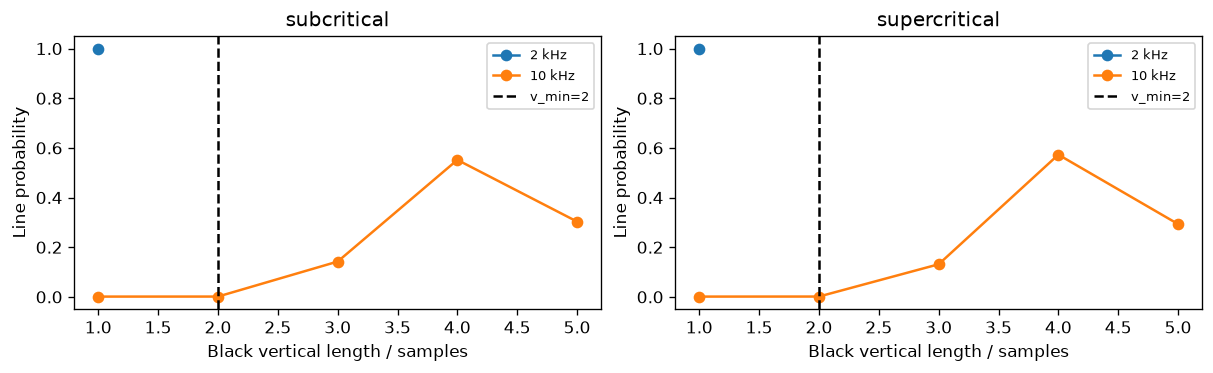

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
for ax, name in zip(axes, CONFIGS, strict=True):
    estimate = embedding_results[(name, 49)]
    for label_name, record, factor in (
        ("2 kHz", records[(name, 49)], 1),
        ("10 kHz", sampling_records[(name, 49)], 5),
    ):
        _, signal = retained_signal(record, length=0.15)
        embedded = delay_embed(
            normalize_scalar(signal), estimate["m"], estimate["tau"] * factor
        )
        matrix, _ = fixed_rr_plot(embedded)
        lines = extract_lines(matrix)["vertical"]
        lengths, counts = np.unique(lines, return_counts=True)
        ax.plot(lengths, counts / counts.sum(), "o-", label=label_name)
    ax.axvline(2, color="black", ls="--", label="v_min=2")
    ax.set(
        xlabel="Black vertical length / samples",
        ylabel="Line probability",
        title=name,
    )
    ax.legend(fontsize=8)
plt.show()

**Figure:** matched-trajectory sampling and black-vertical-line resolution.
**Observation:** the coarse saturated records have singleton black runs; the
finer recording resolves multi-sample runs while the underlying numerical states
match exactly at shared times. **Scientific meaning:** undefined TT at v_min=2
can be an estimator-resolution effect rather than a physical transition.
**Reproduction status:** diagnostic only; amplitude and RQA statistical
convergence are separate from this deterministic sampling check.

## 10. Numerical and methodological audit

Verify the 24 coarse and 120 refined-baseline windows, their vector counts, recurrence calibration,
measure ranges and strict invalid-window accounting. A compact manifest records
versions, model and numerical choices plus retained-signal fingerprints; it is
printed here and does not create files. The stochastic simulation, estimator
checks and educational pilot are executed; no critical-point search or fitting
is hidden in this audit.

In [34]:
import inspect

window_count = 0
undefined_total = 0
largest_n = 0
audit_windows = [
    (name, alpha, windows, 1)
    for (name, alpha), windows in pilot_windows.items()
] + [
    (name, alpha, windows, 5)
    for (name, alpha), windows in baseline_windows.items()
]
for name, alpha, windows, factor in audit_windows:
    estimate = embedding_results[(name, alpha)]
    assert len(windows) == (4 if factor == 1 else 20)
    for w in windows:
        expected_n = WINDOW - (estimate["m"] - 1) * estimate["tau"] * factor
        assert w["N"] == expected_n and w["raw_samples"] == 1500
        assert abs(w["calibration_rr"] - TARGET_RR) < 2 / w["N"] ** 2
        assert abs(w["RR"] - w["calibration_rr"]) < 1e-15
        for key in ("RR", "DET", "LAM"):
            assert np.isnan(w[key]) or 0 <= w[key] <= 1
        for key in ("L", "Entr", "TT", "RT", "RTE"):
            assert np.isnan(w[key]) or w[key] >= 0
        undefined_total += len(w["undefined"])
        largest_n = max(largest_n, w["N"])
        window_count += 1
    means, invalid = aggregate_rqa(windows)
    for key in METRICS:
        assert bool(invalid[key]) == bool(np.isnan(means[key]))
for record in records.values():
    assert np.all(np.isfinite(record["eta"]))
    assert np.all(np.isfinite(record["scaled_velocity"]))
    assert len(retained_signal(record)[1]) == 6000
source_functions = (
    fixed_epsilon_plot,
    black_runs,
    validate_binary,
    rng_for,
    simulate_hopf,
    retained_signal,
    aggregate_innovations,
    normalize_scalar,
    eligible_line_summary,
    first_ami_minimum,
    working_dimension,
    hopf_drift,
    linear_step,
    linear_innovations,
    integrate_split,
    delay_embed,
    ami_curve,
    cao_statistics,
    fixed_rr_plot,
    extract_lines,
    rqa_statistics,
    rqa_windows,
    aggregate_rqa,
)
source = "\n".join(inspect.getsource(f) for f in source_functions)
manifest = {
    "model": MODEL,
    "configurations": CONFIGS,
    "integrator": "symmetric exact-linear-noise split",
    "h": H,
    "coarse_output_dt": OUTPUT_DT,
    "final_baseline_output_dt": BASELINE_SAMPLE_DT,
    "baseline_physical_delay": "coarse estimated tau * 0.5 ms",
    "baseline_retained_windows": 20,
    "discard": DISCARD,
    "retained": RETAIN,
    "initial_eta_v": [0, 0],
    "master_seed": MASTER_SEED,
    "rng": "PCG64 + SeedSequence keys",
    "raw_window": 1500,
    "window_step": 1500,
    "RR_target": TARGET_RR,
    "minimum_lines": 2,
    "entropy": "natural log; eligible-line conditional probabilities",
    "white_policy": "complete bounded white cells; exclude censored edges",
    "diagonal_policy": "RR/verticals keep LOI; diagonal runs omit LOI",
    "python": platform.python_version(),
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "source_sha256": hashlib.sha256(source.encode()).hexdigest(),
    "retained_signal_sha256": {
        f"{name}:{alpha}": hashlib.sha256(
            retained_signal(record)[1].tobytes()
        ).hexdigest()
        for (name, alpha), record in records.items()
    },
}
print(json.dumps(manifest, indent=2))
print("Checked RQA windows:", window_count)
print("Undefined metric/window combinations:", undefined_total)
print("Largest primary RP:", largest_n, "x", largest_n)
print(
    f"Dense distance matrix: {largest_n**2 * 8 / 2**20:.2f} MiB"
    " plus temporary arrays."
)
print("All analytical, coupling, embedding, RP and RQA tests passed.")

{
  "model": {
    "omega": 753.9822368615503,
    "beta": 50.0,
    "Gamma": 10.0
  },
  "configurations": {
    "subcritical": {
      "K": 9.0,
      "gamma": 0.7
    },
    "supercritical": {
      "K": -9.0,
      "gamma": -0.7
    }
  },
  "integrator": "symmetric exact-linear-noise split",
  "h": 5e-05,
  "coarse_output_dt": 0.0005,
  "final_baseline_output_dt": 0.0001,
  "baseline_physical_delay": "coarse estimated tau * 0.5 ms",
  "baseline_retained_windows": 20,
  "discard": 30.0,
  "retained": 3.0,
  "initial_eta_v": [
    0,
    0
  ],
  "master_seed": 2025083107,
  "rng": "PCG64 + SeedSequence keys",
  "raw_window": 1500,
  "window_step": 1500,
  "RR_target": 0.05,
  "minimum_lines": 2,
  "entropy": "natural log; eligible-line conditional probabilities",
  "white_policy": "complete bounded white cells; exclude censored edges",
  "diagonal_policy": "RR/verticals keep LOI; diagonal runs omit LOI",
  "python": "3.12.10",
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "source_sha2

### Phase 1 Conclusions and Phase 2 Handoff

Executed findings, discrepancies and the chosen Phase 2 baseline are finalized
after inspection of the pilot and all numerical checks. Phase 1 only is included.